# CrediScope Analysis

**Clear decisions. Clear reasons.**

This notebook explores the CreditSense dataset and prepares the data for machine learning.

The aim is to understand the structure of the dataset, identify any issues that need preprocessing, and prepare the features before training a credit-risk model.

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/creditsense_applications.csv")
dictionary = pd.read_csv("../data/creditsense_data_dictionary.csv")

In [3]:
df.shape

(6000, 27)

In [4]:
df.head()

,application_id,age_years,sex,marital_status,residency_status,num_dependents,region,employment_status,months_in_current_job,annual_income_gbp,...,has_savings_account,savings_balance_gbp,checking_account_status,loan_amount_gbp,loan_term_months,loan_purpose,has_guarantor,previous_application_declined,application_channel,default_within_24m
0,APP-000001,34,Female,Married,Settled Status,1,North West,Permanent,19,66550,...,Yes,380.0,500 GBP or more,13100,36,Home improvement,No,No,Online,0
1,APP-000002,43,Female,Married,Settled Status,1,South East,Permanent,29,20820,...,No,0.0,Overdrawn,9700,60,Medical,No,No,Branch,1
2,APP-000003,47,Male,Single,UK Citizen,0,South East,Permanent,115,32710,...,No,0.0,500 GBP or more,8600,36,Home improvement,No,No,Online,0
3,APP-000004,63,Male,Married,UK Citizen,1,London,Permanent,146,47300,...,Yes,NaN,0 to 500 GBP,25600,36,Home improvement,No,No,Online,0
4,APP-000005,40,Male,Single,UK Citizen,1,Yorkshire,Permanent,22,41400,...,Yes,860.0,0 to 500 GBP,3500,36,Car,Yes,No,Branch,0


In [5]:
df.columns.tolist()

['application_id',
 'age_years',
 'sex',
 'marital_status',
 'residency_status',
 'num_dependents',
 'region',
 'employment_status',
 'months_in_current_job',
 'annual_income_gbp',
 'monthly_expenses_gbp',
 'housing_status',
 'years_at_current_address',
 'existing_debt_gbp',
 'num_existing_credit_lines',
 'num_late_payments_24m',
 'credit_history',
 'has_savings_account',
 'savings_balance_gbp',
 'checking_account_status',
 'loan_amount_gbp',
 'loan_term_months',
 'loan_purpose',
 'has_guarantor',
 'previous_application_declined',
 'application_channel',
 'default_within_24m']

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 27 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   application_id                 6000 non-null   str    
 1   age_years                      6000 non-null   int64  
 2   sex                            6000 non-null   str    
 3   marital_status                 6000 non-null   str    
 4   residency_status               6000 non-null   str    
 5   num_dependents                 6000 non-null   int64  
 6   region                         6000 non-null   str    
 7   employment_status              6000 non-null   str    
 8   months_in_current_job          6000 non-null   int64  
 9   annual_income_gbp              6000 non-null   int64  
 10  monthly_expenses_gbp           6000 non-null   int64  
 11  housing_status                 6000 non-null   str    
 12  years_at_current_address       5832 non-null   float64
 13 

In [7]:
df.isna().sum().sort_values(ascending=False)

savings_balance_gbp              258
years_at_current_address         168
application_id                     0
marital_status                     0
residency_status                   0
num_dependents                     0
region                             0
employment_status                  0
months_in_current_job              0
age_years                          0
sex                                0
monthly_expenses_gbp               0
annual_income_gbp                  0
existing_debt_gbp                  0
housing_status                     0
num_existing_credit_lines          0
num_late_payments_24m              0
credit_history                     0
has_savings_account                0
checking_account_status            0
loan_amount_gbp                    0
loan_term_months                   0
loan_purpose                       0
has_guarantor                      0
previous_application_declined      0
application_channel                0
default_within_24m                 0
d

## Missing Values

Only two features contain missing values:

- `savings_balance_gbp` has 258 missing values.
- `years_at_current_address` has 168 missing values.

All other columns are complete.

These missing values will be investigated before deciding how they should be handled during preprocessing.

In [8]:
df["default_within_24m"].value_counts()

default_within_24m
0    4467
1    1533
Name: count, dtype: int64

In [9]:
df["default_within_24m"].value_counts(normalize=True) * 100

default_within_24m
0    74.45
1    25.55
Name: proportion, dtype: float64

## Target Variable

The target variable is `default_within_24m`.

- `0` means the applicant did not default within 24 months.
- `1` means the applicant did default within 24 months.

The target is moderately imbalanced, with 25.55% of applicants in the default class.

In [10]:
dictionary.head(30)

,column,type,description,protected_attribute,notes
0,application_id,string,Unique application reference,No,Identifier only - must NOT be used as a feature
1,age_years,integer,Applicant age at application,Yes,Protected characteristic under Equality Act 2010
2,sex,categorical,Female / Male,Yes,Protected characteristic under Equality Act 2010
3,marital_status,categorical,Single / Married / Divorced / Widowed,Yes,Correlates strongly with age
4,residency_status,categorical,UK Citizen / Settled Status / Visa Holder,Yes,Proxy for nationality - protected characteristic
5,num_dependents,integer,Number of financial dependents,No,Correlates with marital_status
6,region,categorical,UK region of residence,No,Can act as a proxy for other attributes
7,employment_status,categorical,Permanent / Fixed-term / Self-employed / Zero-...,No,Retired appears only in older applicants
8,months_in_current_job,integer,Tenure in current employment (months),No,Zero for unemployed applicants - structural ze...
9,annual_income_gbp,integer,Gross annual income in GBP,No,Not adjusted for region


## Initial Data Dictionary Observations

The data dictionary highlights several features that will need careful handling during preprocessing.

- `application_id` is an identifier and should not be used as a predictive feature.
- `age_years`, `sex`, `marital_status`, `residency_status` and `housing_status` are marked as protected attributes.
- `region` is not marked as protected, but it may act as a proxy for other characteristics.
- `credit_history` is ordinal.
- `checking_account_status` is ordinal, but the `No account` category does not fit naturally on the same ordered scale.
- `months_in_current_job = 0` for unemployed applicants is a structural zero and represents valid information.
- Missing values occur in `years_at_current_address` and `savings_balance_gbp`.

In [11]:
numerical_columns = df.select_dtypes(
   include=["int64", "float64"] 
).columns.tolist()

categorical_columns = df.select_dtypes(
   include="str" 
).columns.tolist()

In [12]:
print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)


Numerical Columns:
['age_years', 'num_dependents', 'months_in_current_job', 'annual_income_gbp', 'monthly_expenses_gbp', 'years_at_current_address', 'existing_debt_gbp', 'num_existing_credit_lines', 'num_late_payments_24m', 'savings_balance_gbp', 'loan_amount_gbp', 'loan_term_months', 'default_within_24m']

Categorical Columns:
['application_id', 'sex', 'marital_status', 'residency_status', 'region', 'employment_status', 'housing_status', 'credit_history', 'has_savings_account', 'checking_account_status', 'loan_purpose', 'has_guarantor', 'previous_application_declined', 'application_channel']


In [13]:
target_column = "default_within_24m"
id_column = "application_id"

numerical_features = [
    col for col in numerical_columns 
    if col not in [target_column, id_column]
]

categorical_features = [
    col for col in categorical_columns
    if col != id_column
]

In [14]:
print("Numerical Columns:") 
print(numerical_features)

print("\nCategorical Columns:")
print(categorical_features)

Numerical Columns:
['age_years', 'num_dependents', 'months_in_current_job', 'annual_income_gbp', 'monthly_expenses_gbp', 'years_at_current_address', 'existing_debt_gbp', 'num_existing_credit_lines', 'num_late_payments_24m', 'savings_balance_gbp', 'loan_amount_gbp', 'loan_term_months']

Categorical Columns:
['sex', 'marital_status', 'residency_status', 'region', 'employment_status', 'housing_status', 'credit_history', 'has_savings_account', 'checking_account_status', 'loan_purpose', 'has_guarantor', 'previous_application_declined', 'application_channel']


## Feature Groups

The dataset contains 25 predictive features.

- 12 numerical features
- 13 categorical features
- `application_id` is excluded because it is only an identifier
- `default_within_24m` is the target variable

# Data Preprocessing

This section prepares the dataset for machine learning.

A separate working copy of the original dataframe will be used so that the raw data remains unchanged while preprocessing decisions are applied.

In [15]:
df_clean = df.copy()

In [16]:
print("Original dataset shape:", df.shape)
print("Working copy shape:", df_clean.shape)

Original dataset shape: (6000, 27)
Working copy shape: (6000, 27)


In [17]:
df_clean.isna().sum()[df_clean.isna().sum() >0]

years_at_current_address    168
savings_balance_gbp         258
dtype: int64

## Missing Value Investigation

Two features contain missing values:

- `years_at_current_address`
- `savings_balance_gbp`

Before filling these values, their distributions and meanings will be checked to choose an appropriate preprocessing method.

In [18]:
df_clean["years_at_current_address"].describe()

count    5832.000000
mean        5.169513
std         4.893061
min         0.000000
25%         1.900000
50%         3.700000
75%         6.800000
max        40.000000
Name: years_at_current_address, dtype: float64

In [19]:
df_clean["savings_balance_gbp"].describe()

count      5742.000000
mean       3206.849530
std        7875.004884
min           0.000000
25%           0.000000
50%         610.000000
75%        3250.000000
max      160000.000000
Name: savings_balance_gbp, dtype: float64

In [20]:
df_clean.groupby("has_savings_account")["savings_balance_gbp"].apply(
    lambda x: x.isna().sum()
)

has_savings_account
No       0
Yes    258
Name: savings_balance_gbp, dtype: int64

## Missing Value Decision

The two features with missing values are `years_at_current_address` and `savings_balance_gbp`.

Both features are positively skewed, so the median is preferred to the mean because it is less affected by large values.

For `savings_balance_gbp`, all missing values occur among applicants who do have a savings account. Applicants without a savings account already have a meaningful balance of £0, so those zeros must be preserved.

In [21]:
df_clean["years_at_current_address"] = (
    df_clean["years_at_current_address"]
    .fillna(df_clean["years_at_current_address"].median())
)

df_clean["savings_balance_gbp"] = (
    df_clean["savings_balance_gbp"]
    .fillna(df_clean["savings_balance_gbp"].median())
)

In [22]:
df_clean[
    ["years_at_current_address", "savings_balance_gbp"]
].isna().sum()

years_at_current_address    0
savings_balance_gbp         0
dtype: int64

In [23]:
df_clean.isna().sum().sum()

np.int64(0)

### Missing Value Result

Median imputation was applied to the two features containing missing values.

After preprocessing, the working dataset contains no missing values.

In [24]:
df_clean.groupby("employment_status")["months_in_current_job"].describe()

,count,mean,std,min,25%,50%,75%,max
employment_status,,,,,,,,
Fixed-term,606.0,21.016502,13.643140,2.0,11.0,17.0,29.0,89.0
Permanent,4125.0,53.890667,34.846809,3.0,28.0,46.0,73.0,245.0
Retired,77.0,111.389610,44.850382,41.0,74.0,109.0,136.0,242.0
Self-employed,679.0,55.587629,37.494002,3.0,30.0,46.0,72.0,250.0
Unemployed,227.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
Zero-hours,286.0,21.363636,13.552003,1.0,11.0,19.0,30.0,83.0


## Structural Zero Check

The `months_in_current_job` feature contains zero values for unemployed applicants.

All 227 unemployed applicants have `months_in_current_job = 0`, which indicates that these values are structural zeros rather than missing data.

These values will therefore be preserved.

In [25]:
binary_columns = [
    "has_savings_account",
    "has_guarantor",
    "previous_application_declined",
]

In [26]:
for col in binary_columns:
    df_clean[col] = df_clean[col].map({"Yes": 1, "No": 0})

In [27]:
for col in binary_columns:
    print(col, df_clean[col].value_counts())

has_savings_account has_savings_account
1    3495
0    2505
Name: count, dtype: int64
has_guarantor has_guarantor
0    5432
1     568
Name: count, dtype: int64
previous_application_declined previous_application_declined
0    5251
1     749
Name: count, dtype: int64


## Binary Feature Encoding

Three Yes/No categorical features were converted to numerical binary values:

- `has_savings_account`
- `has_guarantor`
- `previous_application_declined`

`Yes` was encoded as `1` and `No` as `0`.

In [28]:
df_clean["credit_history"].value_counts()

credit_history
Existing credits paid    1935
All paid on time         1727
Past delays              1356
No credits taken          882
Critical account          100
Name: count, dtype: int64

## Ordinal Encoding

The `credit_history` feature has categories that represent different levels of credit risk.

An ordinal encoding will be used so that lower values represent better credit history and higher values represent greater risk.

Proposed order:

1. `All paid on time`
2. `Existing credits paid`
3. `No credits taken`
4. `Past delays`
5. `Critical account`

In [29]:
credit_history_mapping = {
    "All paid on time": 0,
    "Existing credits paid": 1,
    "No credits taken": 2,
    "Past delays": 3,
    "Critical account": 4,
}

In [30]:
df_clean["credit_history"].value_counts().sort_index()

credit_history
All paid on time         1727
Critical account          100
Existing credits paid    1935
No credits taken          882
Past delays              1356
Name: count, dtype: int64

In [31]:
df_clean["credit_history"].isna().sum()

np.int64(0)

In [32]:
df_clean["checking_account_status"].value_counts()

checking_account_status
0 to 500 GBP       2185
500 GBP or more    1971
Overdrawn          1252
No account          592
Name: count, dtype: int64

### Checking Account Status

The `checking_account_status` feature contains three naturally ordered categories:

- `Overdrawn`
- `0 to 500 GBP`
- `500 GBP or more`

The category `No account` does not fit naturally on the same ordinal scale.

To preserve this distinction, `No account` will be handled separately rather than being forced into the ordered ranking.

In [33]:
df_clean["has_checking_account"] = (
    df_clean["checking_account_status"] != "No account"
).astype(int)

In [34]:
df_clean["has_checking_account"].value_counts()

has_checking_account
1    5408
0     592
Name: count, dtype: int64

In [35]:
checking_status_mapping = {
    "Overdrawn": 0,
    "0 to 500 GBP": 1,
    "500 GBP or more": 2,
}

In [36]:
df_clean["checking_account_status"] = (
    df_clean["checking_account_status"]
    .map(checking_status_mapping)
)

In [37]:
df_clean["checking_account_status"].value_counts(dropna=False).sort_index()

checking_account_status
0.0    1252
1.0    2185
2.0    1971
NaN     592
Name: count, dtype: int64

In [38]:
df_clean["checking_account_status"] = (
    df_clean["checking_account_status"]
    .fillna(0)
    .astype(int)
)

In [39]:
df_clean[
    ["checking_account_status", "has_checking_account"]
].value_counts().sort_index()

checking_account_status  has_checking_account
0                        0                        592
                         1                       1252
1                        1                       2185
2                        1                       1971
Name: count, dtype: int64

### Checking Account Encoding Result

The ordered checking account categories were encoded numerically, while `No account` was separated using the `has_checking_account` indicator.

This preserves the distinction between:

- applicants with no checking account
- applicants who are overdrawn
- applicants with lower balances
- applicants with higher balances

In [40]:
remaining_categorical = df_clean.select_dtypes(include="object").columns.tolist()

remaining_categorical

C:\Users\test\AppData\Local\Temp\ipykernel_11332\448189261.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  remaining_categorical = df_clean.select_dtypes(include="object").columns.tolist()


['application_id',
 'sex',
 'marital_status',
 'residency_status',
 'region',
 'employment_status',
 'housing_status',
 'credit_history',
 'loan_purpose',
 'application_channel']

In [41]:
df_clean["credit_history"].head(10)

0    Existing credits paid
1         All paid on time
2         No credits taken
3    Existing credits paid
4              Past delays
5    Existing credits paid
6              Past delays
7              Past delays
8         All paid on time
9    Existing credits paid
Name: credit_history, dtype: str

In [42]:
df_clean["credit_history"] = df_clean["credit_history"].map(
    credit_history_mapping
)

In [43]:
df_clean["credit_history"].value_counts().sort_index()

credit_history
0    1727
1    1935
2     882
3    1356
4     100
Name: count, dtype: int64

In [44]:
df_clean["credit_history"].isna().sum()

np.int64(0)

In [45]:
remaining_categorical = df_clean.select_dtypes(include="str").columns.tolist()

remaining_categorical

['application_id',
 'sex',
 'marital_status',
 'residency_status',
 'region',
 'employment_status',
 'housing_status',
 'loan_purpose',
 'application_channel']

In [46]:
nominal_features = [
    "region",
    "employment_status",
    "loan_purpose",
    "application_channel",
]

## Nominal Categorical Features

The following features have categories with no natural ranking:

- `region`
- `employment_status`
- `loan_purpose`
- `application_channel`

These features will be prepared using one-hot encoding.

Other categorical features such as `sex`, `marital_status`, `residency_status` and `housing_status` require a separate modelling decision because of their protected or sensitive nature.

## Protected and Sensitive Attributes

Several categorical features are identified as protected or sensitive within the data dictionary.

These features will not be used directly as predictive inputs in the initial model:

- `sex`
- `marital_status`
- `residency_status`
- `housing_status`

They will be retained in the dataset for later fairness analysis.

`region` is not formally marked as protected, but it may act as a proxy for other characteristics, so its use will be considered carefully.

In [47]:
protected_features = [
    "sex",
    "marital_status",
    "residency_status",
    "housing_status"
]

In [48]:
excluded_features = [
    "application_id",
    "default_within_24m",
] + protected_features

In [49]:
model_features = [
    col for col in df_clean.columns 
    if col not in excluded_features
]

In [50]:
model_features

['age_years',
 'num_dependents',
 'region',
 'employment_status',
 'months_in_current_job',
 'annual_income_gbp',
 'monthly_expenses_gbp',
 'years_at_current_address',
 'existing_debt_gbp',
 'num_existing_credit_lines',
 'num_late_payments_24m',
 'credit_history',
 'has_savings_account',
 'savings_balance_gbp',
 'checking_account_status',
 'loan_amount_gbp',
 'loan_term_months',
 'loan_purpose',
 'has_guarantor',
 'previous_application_declined',
 'application_channel',
 'has_checking_account']

In [51]:
protected_features = [
    "age_years",
    "sex",
    "marital_status",
    "residency_status",
    "housing_status"
]

In [52]:
excluded_features = [
    "application_id",
    "default_within_24m"
] + protected_features

In [53]:
model_features = [
    col for col in df_clean.columns
    if col not in excluded_features
]

In [54]:
model_features

['num_dependents',
 'region',
 'employment_status',
 'months_in_current_job',
 'annual_income_gbp',
 'monthly_expenses_gbp',
 'years_at_current_address',
 'existing_debt_gbp',
 'num_existing_credit_lines',
 'num_late_payments_24m',
 'credit_history',
 'has_savings_account',
 'savings_balance_gbp',
 'checking_account_status',
 'loan_amount_gbp',
 'loan_term_months',
 'loan_purpose',
 'has_guarantor',
 'previous_application_declined',
 'application_channel',
 'has_checking_account']

## Initial Model Feature Set

The initial model excludes:

- `application_id`
- the target variable `default_within_24m`
- protected attributes identified in the data dictionary

The remaining features form the initial modelling feature set.

`region` is retained at this stage, but it may act as a proxy for protected characteristics and will be reviewed during fairness analysis.

In [55]:
nominal_features

['region', 'employment_status', 'loan_purpose', 'application_channel']

In [56]:
df_clean = pd.get_dummies(
    df_clean,
    columns=nominal_features,
    drop_first=True,
    dtype=int
)

In [57]:
df_clean.shape

(6000, 48)

In [58]:
[col for col in df_clean.columns if col.startswith("region_")][:10]

['region_Midlands',
 'region_North East',
 'region_North West',
 'region_Northern Ireland',
 'region_Scotland',
 'region_South East',
 'region_South West',
 'region_Wales',
 'region_Yorkshire']

## One-Hot Encoding

The nominal categorical features were converted into binary indicator columns using one-hot encoding.

The encoded features were:

- `region`
- `employment_status`
- `loan_purpose`
- `application_channel`

`drop_first=True` was used so that one category from each feature acts as a reference category, reducing redundant information.

The dataset increased from 27 columns to 48 columns while retaining all 6,000 application records.

In [59]:
df_clean.select_dtypes(include="object").columns.tolist()

C:\Users\test\AppData\Local\Temp\ipykernel_11332\2435950628.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_clean.select_dtypes(include="object").columns.tolist()


['application_id',
 'sex',
 'marital_status',
 'residency_status',
 'housing_status']

### Encoding Check

After one-hot encoding, the only remaining text columns are the application identifier and protected/sensitive attributes.

These columns are not included directly in the initial predictive model.

In [60]:
df_clean["debt_to_income_ratio"] = (
    df_clean["existing_debt_gbp"] /
    df_clean["annual_income_gbp"]
)

In [61]:
df_clean["debt_to_income_ratio"].describe()

count    6000.000000
mean        0.307106
std         0.284312
min         0.000000
25%         0.000000
50%         0.261718
75%         0.560400
max         0.849748
Name: debt_to_income_ratio, dtype: float64

## Feature Engineering

A `debt_to_income_ratio` feature was created by dividing existing debt by annual income.

This provides a relative measure of debt burden, which may be more informative than considering debt or income separately.

In [62]:
df_clean["expenses_to_income_ratio"] = (
    df_clean["monthly_expenses_gbp"] * 12 /
    df_clean["annual_income_gbp"]
)    

In [63]:
df_clean["expenses_to_income_ratio"].describe()

count    6000.000000
mean        0.788505
std         0.359927
min         0.340003
25%         0.566188
50%         0.704567
75%         0.921250
max         4.596923
Name: expenses_to_income_ratio, dtype: float64

In [64]:
df_clean = df_clean.rename(
    columns={"expenses_to_income_ratio": "expense_to_income_ratio"}
)

In [65]:
"expense_to_income_ratio" in df_clean.columns

True

In [66]:
df_clean[df_clean["expense_to_income_ratio"] > 1][
    [
        "annual_income_gbp",
        "monthly_expenses_gbp",
        "expense_to_income_ratio"
    ]
].head(10)    

,annual_income_gbp,monthly_expenses_gbp,expense_to_income_ratio
1,20820,2460,1.417867
16,29280,3140,1.286885
32,17950,1690,1.129805
33,29240,2460,1.009576
52,12560,1330,1.270701
59,16610,2160,1.560506
61,16160,1560,1.158416
68,31540,2700,1.027267
73,25960,2390,1.104777
74,12580,1650,1.573927


In [67]:
(df_clean["expense_to_income_ratio"] > 1).sum()

np.int64(1123)

### Expense-to-Income Ratio

An `expense_to_income_ratio` feature was created by annualising monthly expenses and dividing them by annual income.

Some applicants have a ratio greater than 1, meaning their stated annual expenses exceed their annual income.

This occurs for 1,123 applicants, so it is treated as a meaningful characteristic of the dataset rather than an isolated data error.

## Train/Test Split

The dataset will now be separated into training and testing sets.

The training data will be used to fit the machine-learning model, while the test data will be kept separate so that model performance can be evaluated on unseen applications.

In [68]:
from sklearn.model_selection import train_test_split

In [69]:
X = df_clean.drop(
    columns=[
        "application_id",
        "default_within_24m",
        "age_years",
        "sex",
        "marital_status",
        "residency_status",
        "housing_status"
    ]
)

y = df_clean["default_within_24m"]

In [70]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (6000, 43)
y shape: (6000,)


In [71]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [72]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (4800, 43)
X_test: (1200, 43)
y_train: (4800,)
y_test: (1200,)


In [73]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
default_within_24m
0    74.458333
1    25.541667
Name: proportion, dtype: float64

Testing target distribution:
default_within_24m
0    74.416667
1    25.583333
Name: proportion, dtype: float64


### Split Verification

A stratified 80/20 train-test split was used.

The class distribution was preserved across both datasets, with approximately 74% non-default cases and 26% default cases in both the training and testing sets.

This helps ensure that model evaluation is performed on a representative test set.

In [74]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [75]:
baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

In [76]:
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](43,)","['num_dependents','months_in_current_job','annual_income_gbp',..., 'application_channel_Phone','debt_to_income_ratio', 'expense_to_income_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,43
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [77]:
y_pred = baseline_model.predict(X_test)

In [78]:
from sklearn.metrics import accuracy_score

In [79]:
accurancy = accuracy_score(y_test, y_pred)

print("Baseline Model Accuracy:", accurancy)

Baseline Model Accuracy: 0.8


In [80]:
from sklearn.metrics import classification_report

In [81]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.92      0.87       893
           1       0.65      0.46      0.54       307

    accuracy                           0.80      1200
   macro avg       0.74      0.69      0.71      1200
weighted avg       0.79      0.80      0.79      1200



### Baseline Classification Performance

The baseline Logistic Regression model achieved an accuracy of 80%.

However, performance differed between the two classes.

For applicants who defaulted (`class 1`), the model achieved:

- Precision: 0.65
- Recall: 0.46
- F1-score: 0.54

The relatively low recall means the model fails to identify more than half of the applicants who later default.

This shows why accuracy alone is not sufficient for evaluating the model.


In [82]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, y_pred)

array([[818,  75],
       [165, 142]])

### Confusion Matrix Interpretation

The confusion matrix for the baseline Logistic Regression model produced:

- 818 true negatives
- 75 false positives
- 165 false negatives
- 142 true positives

The most significant weakness is the 165 false negatives. These are applicants who actually defaulted but were predicted as non-default.

This supports the earlier finding that the baseline model has relatively low recall for the default class and may fail to identify a substantial number of higher-risk applicants.

In [83]:
from sklearn.metrics import roc_auc_score

In [84]:
y_prob = baseline_model.predict_proba(X_test)[:, 1]

In [85]:
roc_auc = roc_auc_score(y_test, y_prob)

print("Baseline ROC AUC Score:", roc_auc)

Baseline ROC AUC Score: 0.8111259853146624


### ROC-AUC

The baseline Logistic Regression model achieved a ROC-AUC score of approximately 0.81.

This indicates that the model has a reasonably strong ability to distinguish between applicants who default and those who do not.

However, this does not remove the concern identified in the confusion matrix, where the model missed a substantial number of actual default cases.

In [86]:
from sklearn.ensemble import RandomForestClassifier

In [87]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)    

In [88]:
random_forest_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [89]:
rf_pred = random_forest_model.predict(X_test)

In [90]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.795


In [91]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86       893
           1       0.60      0.60      0.60       307

    accuracy                           0.80      1200
   macro avg       0.73      0.73      0.73      1200
weighted avg       0.80      0.80      0.80      1200



In [92]:
confusion_matrix(y_test, rf_pred)

array([[770, 123],
       [123, 184]])

### Random Forest Confusion Matrix

The Random Forest confusion matrix produced:

- 770 true negatives
- 123 false positives
- 123 false negatives
- 184 true positives

Compared with the Logistic Regression baseline, the Random Forest identifies more applicants who actually default, reducing false negatives from 165 to 123.

However, this improvement comes at a cost, as false positives increase from 75 to 123.

This demonstrates a trade-off between identifying more high-risk applicants and potentially classifying more low-risk applicants as likely to default.

In [93]:
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

rf_roc_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest ROC-AUC:", rf_roc_auc)

Random Forest ROC-AUC: 0.8188917786183526


### Baseline Model Comparison

The Logistic Regression and Random Forest models produced similar overall accuracy, but their error patterns differed.

The Random Forest achieved slightly lower accuracy but improved recall for the default class from 0.46 to 0.60 and improved the F1-score from 0.54 to 0.60.

It also reduced false negatives from 165 to 123, meaning it identified more applicants who later defaulted.

However, false positives increased from 75 to 123, meaning more applicants who would not default were incorrectly classified as higher risk.

The Random Forest also achieved a slightly higher ROC-AUC score of approximately 0.819 compared with 0.811 for Logistic Regression.

This highlights a trade-off between improved detection of default risk and the increased likelihood of incorrectly flagging lower-risk applicants.

## Model Selection and Constraints

The Random Forest currently provides the stronger predictive performance for identifying applicants who default.

It improves recall and F1-score for the default class and reduces the number of false negatives compared with Logistic Regression.

However, Random Forest is less transparent because predictions are produced from many decision trees rather than a single set of easily interpretable coefficients.

Logistic Regression is easier to explain and audit, which is important in a regulated credit-risk environment.

Therefore, model selection should not be based on predictive performance alone. The final choice must consider:

- predictive performance
- false positives and false negatives
- explainability
- fairness
- regulatory defensibility
- suitability for adverse-action explanations

At this stage, Random Forest is the stronger predictive candidate, while Logistic Regression remains the stronger candidate for transparency and interpretability.

In [94]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance.head(10)

,feature,importance
42,expense_to_income_ratio,0.176547
2,annual_income_gbp,0.096686
41,debt_to_income_ratio,0.067738
12,loan_amount_gbp,0.066052
3,monthly_expenses_gbp,0.060932
5,existing_debt_gbp,0.057495
1,months_in_current_job,0.054789
4,years_at_current_address,0.051248
7,num_late_payments_24m,0.046247
13,loan_term_months,0.037004


### Random Forest Feature Importance

The most important feature in the Random Forest model was `expense_to_income_ratio`, followed by `annual_income_gbp`, `debt_to_income_ratio`, `loan_amount_gbp`, and `monthly_expenses_gbp`.

This suggests that the model relies strongly on affordability and financial-pressure variables when distinguishing between lower-risk and higher-risk applicants.

Other influential features included existing debt, employment stability, residential stability, recent late payments, and loan term.

Random Forest feature importance indicates how useful each feature was when building decision trees, but it does not show the direction of the relationship. Therefore, a high importance score does not mean that increasing a feature necessarily increases default risk.

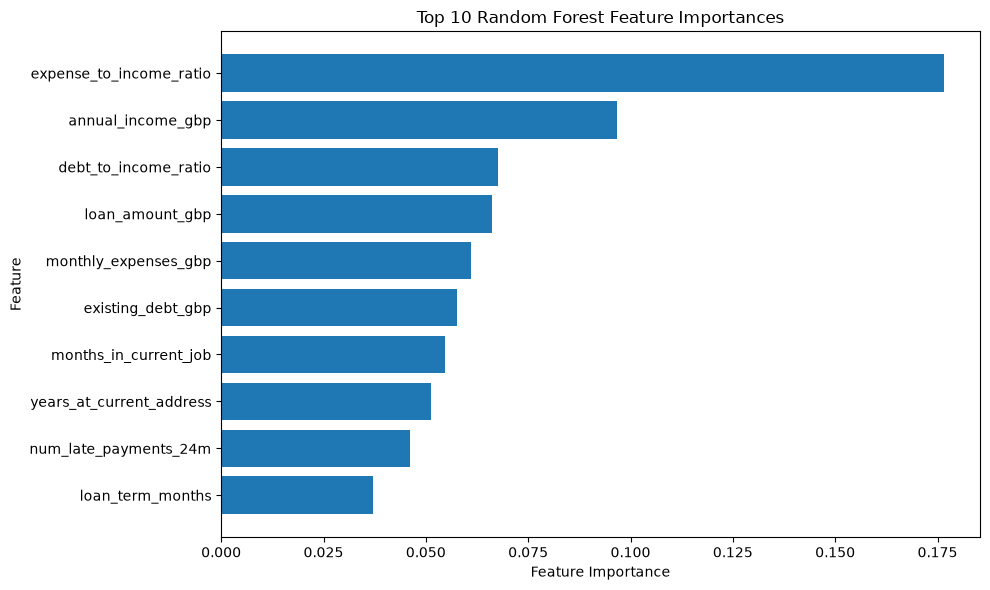

In [95]:
top_features = feature_importance.head(10).sort_values(
    by="importance",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

In [96]:
errors = X_test.copy()

errors["actual"] = y_test
errors["predicted"] = rf_pred

In [97]:
errors[errors["actual"] != errors["predicted"]].head()

,num_dependents,months_in_current_job,annual_income_gbp,monthly_expenses_gbp,years_at_current_address,existing_debt_gbp,num_existing_credit_lines,num_late_payments_24m,credit_history,has_savings_account,...,loan_purpose_Home improvement,loan_purpose_Medical,loan_purpose_Other,application_channel_Broker,application_channel_Online,application_channel_Phone,debt_to_income_ratio,expense_to_income_ratio,actual,predicted
1509,3,72,21280,1990,0.7,0,0,3,2,1,...,0,0,0,1,0,0,0.000000,1.122180,1,0
4471,1,86,28680,2510,1.8,0,5,0,1,0,...,0,1,0,0,1,0,0.000000,1.050209,0,1
1507,1,18,16320,2030,2.1,0,2,0,0,1,...,1,0,0,0,1,0,0.000000,1.492647,1,0
3981,1,62,19160,1000,26.3,4490,1,2,3,1,...,0,0,0,0,1,0,0.234342,0.626305,1,0
4427,2,0,6500,1960,1.6,4770,5,3,1,0,...,1,0,0,0,1,0,0.733846,3.618462,0,1


In [98]:
errors["default_probability"] = rf_prob

In [99]:
false_negatives = errors[
    (errors["actual"] == 1) &
    (errors["predicted"] == 0)
]

false_negatives.sort_values(
    by="default_probability"
).head()

,num_dependents,months_in_current_job,annual_income_gbp,monthly_expenses_gbp,years_at_current_address,existing_debt_gbp,num_existing_credit_lines,num_late_payments_24m,credit_history,has_savings_account,...,loan_purpose_Medical,loan_purpose_Other,application_channel_Broker,application_channel_Online,application_channel_Phone,debt_to_income_ratio,expense_to_income_ratio,actual,predicted,default_probability
5757,1,72,43040,1930,4.9,0,2,1,0,1,...,0,0,0,0,1,0.0,0.538104,1,0,0.010
3767,0,34,116480,4570,8.5,0,3,0,1,0,...,0,0,0,1,0,0.0,0.470810,1,0,0.030
2006,1,19,89150,2730,9.1,0,0,0,2,1,...,0,0,0,1,0,0.0,0.367471,1,0,0.045
1178,0,105,32980,1760,8.5,0,0,1,2,0,...,0,0,0,0,0,0.0,0.640388,1,0,0.055
1687,0,27,35590,1800,14.3,0,3,1,1,1,...,0,0,0,1,0,0.0,0.606912,1,0,0.065


In [100]:
X_test.loc[5757].to_frame(name="Applicant 5757")

,Applicant 5757
num_dependents,1.000000
months_in_current_job,72.000000
annual_income_gbp,43040.000000
monthly_expenses_gbp,1930.000000
years_at_current_address,4.900000
existing_debt_gbp,0.000000
num_existing_credit_lines,2.000000
num_late_payments_24m,1.000000
credit_history,0.000000
has_savings_account,1.000000


### Example of a Badly Handled Applicant

Applicant 5757 provides an example of a significant model error.

The applicant actually defaulted within 24 months, but the Random Forest assigned only a 1% probability of default and predicted that they would not default.

Several features appear relatively low-risk, including permanent employment, six years in the current job, no existing debt, no previous declined application, and a good encoded credit history.

The applicant did have one late payment in the previous 24 months and a relatively small savings balance, but these were not sufficient for the model to correctly identify the eventual default.

This example demonstrates an important limitation of the system. Even when the model is highly confident, its prediction may still be incorrect. The model should therefore support human decision-making rather than be treated as an infallible automated decision maker.

In [101]:
false_positives = errors[
    (errors["actual"] == 0) &
    (errors["predicted"] == 1)
]

false_positives.sort_values(
    by="default_probability",
    ascending=False
).head()

,num_dependents,months_in_current_job,annual_income_gbp,monthly_expenses_gbp,years_at_current_address,existing_debt_gbp,num_existing_credit_lines,num_late_payments_24m,credit_history,has_savings_account,...,loan_purpose_Medical,loan_purpose_Other,application_channel_Broker,application_channel_Online,application_channel_Phone,debt_to_income_ratio,expense_to_income_ratio,actual,predicted,default_probability
4851,1,0,17160,1830,5.7,8570,4,2,1,1,...,0,0,0,1,0,0.499417,1.279720,0,1,0.905
4065,1,30,19500,1780,5.9,15290,1,3,1,1,...,0,0,0,0,0,0.784103,1.095385,0,1,0.870
5679,1,15,28000,2460,4.3,21910,3,0,1,0,...,0,0,0,0,0,0.782500,1.054286,0,1,0.850
1373,0,63,22520,2210,4.8,6080,4,2,1,1,...,0,0,0,1,0,0.269982,1.177620,0,1,0.835
4202,1,19,17150,1750,3.8,4680,5,4,3,0,...,0,0,0,1,0,0.272886,1.224490,0,1,0.820


In [102]:
X_test.loc[4851].to_frame(name="Applicant 4851")

,Applicant 4851
num_dependents,1.000000
months_in_current_job,0.000000
annual_income_gbp,17160.000000
monthly_expenses_gbp,1830.000000
years_at_current_address,5.700000
existing_debt_gbp,8570.000000
num_existing_credit_lines,4.000000
num_late_payments_24m,2.000000
credit_history,1.000000
has_savings_account,1.000000


### Example of a False Positive

Applicant 4851 provides an example of a confident false positive.

The Random Forest assigned this applicant a 90.5% probability of default, but the applicant did not default within 24 months.

The applicant had several characteristics that could be interpreted as higher risk, including unemployment, relatively low income, high monthly expenses, existing debt, multiple credit lines, recent late payments, and a high expense-to-income ratio.

However, the applicant also had savings, no previous declined application, an existing checking account, and a stable residential history.

This example demonstrates that even a high predicted probability does not guarantee that an applicant will default.

In a real lending environment, this type of error could lead to an applicant being unfairly declined or offered less favourable terms. For this reason, model predictions should be supported by explanation, review, and appropriate human oversight.

In [103]:
from sklearn.inspection import permutation_importance

In [104]:
permutation_result = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42
)

In [105]:
permutation_importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": permutation_result.importances_mean
})

permutation_importance_df = permutation_importance_df.sort_values(
    by="importance",
    ascending=False
)

permutation_importance_df.head(10)

,feature,importance
42,expense_to_income_ratio,0.083333
13,loan_term_months,0.012000
41,debt_to_income_ratio,0.007250
1,months_in_current_job,0.006500
12,loan_amount_gbp,0.006000
2,annual_income_gbp,0.004083
32,loan_purpose_Debt consolidation,0.003417
29,employment_status_Unemployed,0.002667
21,region_Scotland,0.001417
35,loan_purpose_Home improvement,0.001250


### Permutation Importance

Permutation importance was used as an additional explainability method to assess how much each feature contributes to predictive performance on the test set.

The most influential feature was `expense_to_income_ratio`, which produced the largest reduction in model performance when its values were shuffled.

Other influential features included `loan_term_months`, `debt_to_income_ratio`, `months_in_current_job`, `loan_amount_gbp`, and `annual_income_gbp`.

The ranking differs slightly from the Random Forest's built-in feature importance because the two methods measure importance differently.

Permutation importance provides a useful additional check because it measures the effect of disturbing each feature on the model's predictive performance.

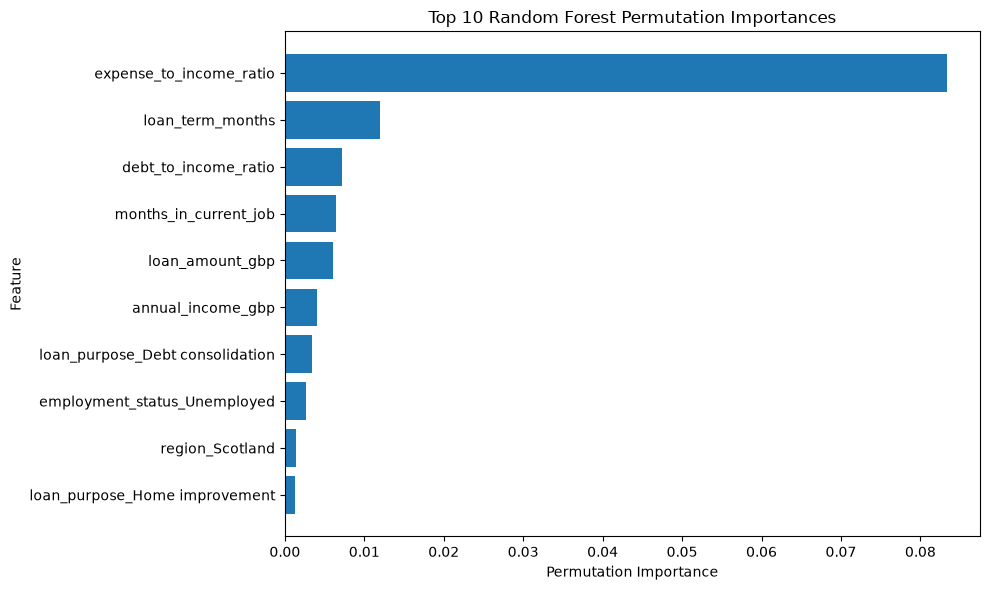

In [106]:
top_permutation_features = permutation_importance_df.head(10).sort_values(
    by="importance",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_permutation_features["feature"],
    top_permutation_features["importance"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest Permutation Importances")
plt.tight_layout()
plt.show()

## Individual Prediction Explainability

Global feature importance shows which features are influential across the model as a whole.

However, a credit decision also requires an explanation of why the model produced a particular prediction for an individual applicant.

This section investigates local explanations that can identify which applicant characteristics contributed most strongly to an individual risk prediction.

In [107]:
import shap

In [108]:
print(shap.__version__)

0.54.1


In [109]:
explainer = shap.TreeExplainer(random_forest_model)

In [110]:
shap_values = explainer(X_test.loc[[4851]])

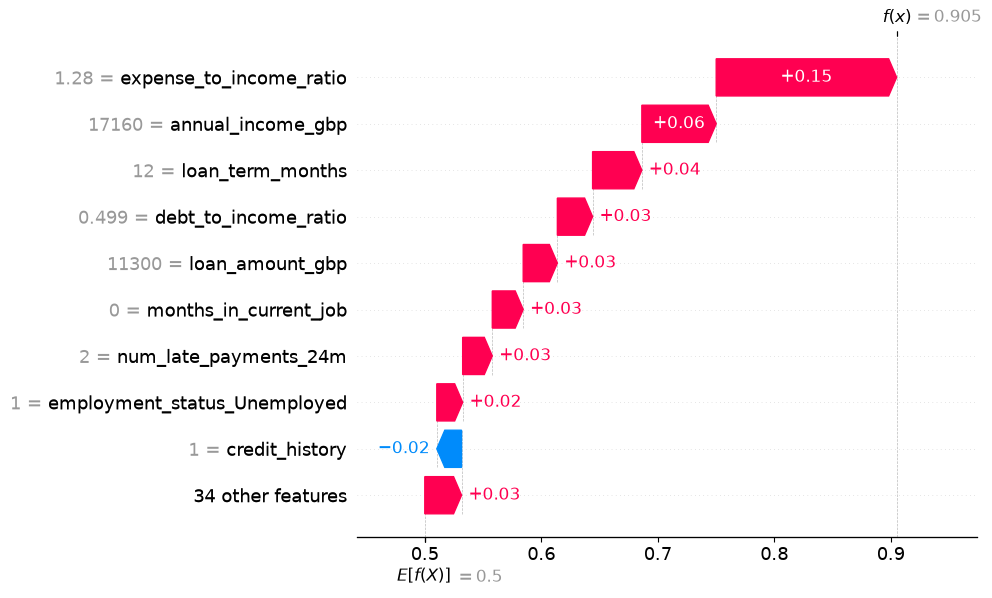

In [111]:
shap.plots.waterfall(shap_values[0, :, 1])

### Local Explanation – Applicant 4851

SHAP was used to explain the Random Forest prediction for Applicant 4851.

The model predicted a default probability of 90.5%.

The strongest factor increasing the predicted risk was the applicant's expense-to-income ratio. Other factors increasing the prediction included annual income, loan term, debt-to-income ratio, loan amount, unemployment, no current job tenure, and recent late payments.

The applicant's encoded credit history slightly reduced the predicted default risk.

This demonstrates how SHAP can provide an individual explanation by showing which features pushed a prediction towards higher or lower estimated default risk.

### Plain-English Explanation – Applicant 4851

The model identified several factors that increased the estimated risk of default for this application.

The main factors were:

- high monthly expenses compared with annual income
- existing debt relative to income
- unemployment at the time of application
- recent late payments
- the requested loan amount
- the selected loan term

Some factors reduced the estimated risk slightly, including the applicant's credit history.

This explanation is intended to make the model's reasoning easier to understand. It should support, rather than replace, appropriate human review of the lending decision.

In [112]:
def explain_prediction(shap_explanation, feature_values, top_n=5):
    contributions = pd.DataFrame({
        "feature": feature_values.index,
        "value": feature_values.values,
        "shap_value": shap_explanation.values
    })

    contributions["absolute_shap"] = contributions["shap_value"].abs()

    return contributions.sort_values(
        by="absolute_shap",
        ascending=False
    ).head(top_n)

In [113]:
top_reasons_4851 = explain_prediction(
    shap_values[0, :, 1],
    X_test.loc[4851],
    top_n=5
)

top_reasons_4851

,feature,value,shap_value,absolute_shap
42,expense_to_income_ratio,1.279720,0.154885,0.154885
2,annual_income_gbp,17160.000000,0.063830,0.063830
13,loan_term_months,12.000000,0.042276,0.042276
41,debt_to_income_ratio,0.499417,0.030244,0.030244
12,loan_amount_gbp,11300.000000,0.029326,0.029326


In [114]:
feature_labels = {
    "expense_to_income_ratio": "high expenses compared with income",
    "annual_income_gbp": "annual income",
    "loan_term_months": "loan term",
    "debt_to_income_ratio": "existing debt compared with income",
    "loan_amount_gbp": "requested loan amount"
}

In [115]:
for _, row in top_reasons_4851.iterrows():
    print(feature_labels.get(row["feature"], row["feature"]))

high expenses compared with income
annual income
loan term
existing debt compared with income
requested loan amount


In [116]:
def generate_plain_english_reasons(top_reasons, feature_labels):
    reasons = []

    for _, row in top_reasons.iterrows():
        label = feature_labels.get(row["feature"], row["feature"])

        if row["shap_value"] > 0:
            reasons.append(f"{label} increased the estimated default risk")
        else:
            reasons.append(f"{label} reduced the estimated default risk")

    return reasons

In [117]:
plain_reasons_4851 = generate_plain_english_reasons(
    top_reasons_4851,
    feature_labels
)

for reason in plain_reasons_4851:
    print("-", reason)

- high expenses compared with income increased the estimated default risk
- annual income increased the estimated default risk
- loan term increased the estimated default risk
- existing debt compared with income increased the estimated default risk
- requested loan amount increased the estimated default risk


In [118]:
def predict_applicant(applicant_data):
    prediction = random_forest_model.predict(applicant_data)[0]

    probability = random_forest_model.predict_proba(
        applicant_data
    )[0, 1]

    return prediction, probability

In [119]:
prediction_4851, probability_4851 = predict_applicant(
    X_test.loc[[4851]]
)

print("Prediction:", prediction_4851)
print("Default probability:", probability_4851)

Prediction: 1
Default probability: 0.905


In [120]:
def predict_applicant(applicant_data):
    prediction = random_forest_model.predict(applicant_data)[0]

    probability = random_forest_model.predict_proba(
        applicant_data
    )[0, 1]

    shap_values = explainer(applicant_data)

    top_reasons = explain_prediction(
        shap_values[0, :, 1],
        applicant_data.iloc[0],
        top_n=5
    )

    plain_reasons = generate_plain_english_reasons(
        top_reasons,
        feature_labels
    )

    return prediction, probability, plain_reasons

In [121]:
prediction_4851, probability_4851, reasons_4851 = predict_applicant(
    X_test.loc[[4851]]
)

print("Prediction:", prediction_4851)
print("Default probability:", probability_4851)

for reason in reasons_4851:
    print("-", reason)

Prediction: 1
Default probability: 0.905
- high expenses compared with income increased the estimated default risk
- annual income increased the estimated default risk
- loan term increased the estimated default risk
- existing debt compared with income increased the estimated default risk
- requested loan amount increased the estimated default risk


### Improving Plain-English Explanations

The first version of the explanation function successfully converted SHAP feature contributions into readable text.

However, some phrases were technically correct but too generic for an applicant-facing explanation. For example, a statement such as "annual income increased the estimated default risk" does not explain the relationship in a natural or useful way.

To improve usability, the explanation layer was refined so that technical feature names are translated into clearer, more understandable descriptions.

The SHAP values remain the underlying source of the explanation, while the wording layer improves how the reasons are presented to a non-technical user.

This supports the CrediScope MVP goal of producing explanations that are both technically grounded and easier to understand.

### Refining the Explanation Language

The initial explanation function successfully identified the most influential SHAP features and converted them into readable statements.

However, the first version used a generic sentence structure, which sometimes produced wording that was technically correct but difficult for a non-technical applicant to interpret.

The explanation logic was therefore refined to use more natural feature-specific phrases.

This improves usability while preserving the SHAP values as the underlying evidence for each explanation.

A limitation is that the wording remains rule-based and does not yet account for every possible feature combination. Therefore, explanations should still be reviewed for clarity before being used in a real lending environment.

In [122]:
def generate_plain_english_reasons(top_reasons):
    reasons = []

    for _, row in top_reasons.iterrows():
        feature = row["feature"]
        shap_value = row["shap_value"]

        if feature == "expense_to_income_ratio":
            reason = "expenses were high compared with income"

        elif feature == "annual_income_gbp":
            reason = "income level influenced the estimated risk"

        elif feature == "loan_term_months":
            reason = "the selected loan term influenced the estimated risk"

        elif feature == "debt_to_income_ratio":
            reason = "existing debt was significant compared with income"

        elif feature == "loan_amount_gbp":
            reason = "the requested loan amount influenced the estimated risk"

        else:
            reason = feature_labels.get(feature, feature)

        if shap_value > 0:
            reasons.append(f"{reason} and increased the estimated default risk")
        else:
            reasons.append(f"{reason} and reduced the estimated default risk")

    return reasons

In [123]:
reasons_4851 = generate_plain_english_reasons(
    top_reasons_4851
)

for reason in reasons_4851:
    print("-", reason)

- expenses were high compared with income and increased the estimated default risk
- income level influenced the estimated risk and increased the estimated default risk
- the selected loan term influenced the estimated risk and increased the estimated default risk
- existing debt was significant compared with income and increased the estimated default risk
- the requested loan amount influenced the estimated risk and increased the estimated default risk


### Reducing Repetition in Applicant Explanations

Testing the refined explanation function showed that some statements remained repetitive.

For example, phrases such as "income level influenced the estimated risk and increased the estimated default risk" repeat the same idea twice.

The explanation logic was therefore refined again so that each feature can generate a complete sentence based on whether it increased or reduced the predicted risk.

This produces clearer applicant-facing explanations while retaining the SHAP contribution as the evidence behind each statement.

In [124]:
def generate_plain_english_reasons(top_reasons):
    reasons = []

    for _, row in top_reasons.iterrows():
        feature = row["feature"]
        shap_value = row["shap_value"]

        increased = shap_value > 0

        if feature == "expense_to_income_ratio":
            reason = (
                "expenses were high compared with income, increasing the estimated default risk"
                if increased
                else "expenses compared with income reduced the estimated default risk"
            )

        elif feature == "annual_income_gbp":
            reason = (
                "the applicant's income level increased the estimated default risk"
                if increased
                else "the applicant's income level reduced the estimated default risk"
            )

        elif feature == "loan_term_months":
            reason = (
                "the selected loan term increased the estimated default risk"
                if increased
                else "the selected loan term reduced the estimated default risk"
            )

        elif feature == "debt_to_income_ratio":
            reason = (
                "existing debt relative to income increased the estimated default risk"
                if increased
                else "existing debt relative to income reduced the estimated default risk"
            )

        elif feature == "loan_amount_gbp":
            reason = (
                "the requested loan amount increased the estimated default risk"
                if increased
                else "the requested loan amount reduced the estimated default risk"
            )

        else:
            label = feature_labels.get(feature, feature)

            reason = (
                f"{label} increased the estimated default risk"
                if increased
                else f"{label} reduced the estimated default risk"
            )

        reasons.append(reason)

    return reasons

In [125]:
reasons_4851 = generate_plain_english_reasons(top_reasons_4851)

for reason in reasons_4851:
    print("-", reason)

- expenses were high compared with income, increasing the estimated default risk
- the applicant's income level increased the estimated default risk
- the selected loan term increased the estimated default risk
- existing debt relative to income increased the estimated default risk
- the requested loan amount increased the estimated default risk


### Combining Prediction and Explanation into One MVP Function

The previous steps developed prediction, probability estimation, SHAP explanation, and plain-English reasoning as separate components.

These components are now combined into a single reusable function so that CrediScope can return a complete decision output for an individual applicant.

This is an important step towards the MVP because the same function can later be called directly from the user interface.

Earlier versions are retained in the notebook to show how the solution evolved through iterative development.

In [126]:
def predict_applicant(applicant_data):
    prediction = random_forest_model.predict(applicant_data)[0]

    probability = random_forest_model.predict_proba(
        applicant_data
    )[0, 1]

    shap_values = explainer(applicant_data)

    top_reasons = explain_prediction(
        shap_values[0, :, 1],
        applicant_data.iloc[0],
        top_n=5
    )

    plain_reasons = generate_plain_english_reasons(
        top_reasons
    )

    return prediction, probability, plain_reasons

In [127]:
prediction_4851, probability_4851, reasons_4851 = predict_applicant(
    X_test.loc[[4851]]
)

print("Prediction:", prediction_4851)
print("Default probability:", probability_4851)

for reason in reasons_4851:
    print("-", reason)

Prediction: 1
Default probability: 0.905
- expenses were high compared with income, increasing the estimated default risk
- the applicant's income level increased the estimated default risk
- the selected loan term increased the estimated default risk
- existing debt relative to income increased the estimated default risk
- the requested loan amount increased the estimated default risk


### Creating a CrediScope Decision Summary

The combined prediction function successfully returns the predicted class, estimated default probability, and the main SHAP-based reasons.

However, the raw output is still developer-focused.

The next step is to present the result in a clearer structure that could later be reused by the CrediScope user interface.

This separates the underlying model logic from the way the decision is presented to a user, improving maintainability and supporting the development of the MVP.

In [128]:
def create_decision_summary(prediction, probability, reasons):
    outcome = "Higher Risk" if prediction == 1 else "Lower Risk"

    summary = {
        "risk_category": outcome,
        "default_probability": round(probability * 100, 1),
        "main_reasons": reasons
    }

    return summary

In [129]:
decision_summary_4851 = create_decision_summary(
    prediction_4851,
    probability_4851,
    reasons_4851
)

decision_summary_4851

{'risk_category': 'Higher Risk',
 'default_probability': np.float64(90.5),
 'main_reasons': ['expenses were high compared with income, increasing the estimated default risk',
  "the applicant's income level increased the estimated default risk",
  'the selected loan term increased the estimated default risk',
  'existing debt relative to income increased the estimated default risk',
  'the requested loan amount increased the estimated default risk']}

### Making the MVP Output Interface-Friendly

The decision summary currently returns the default probability as a NumPy floating-point value.

Although this works correctly in Python, a standard Python `float` is more suitable for later use in interfaces, APIs, or JSON output.

The summary function is therefore refined so that the probability is converted into a standard Python data type.

In [130]:
def create_decision_summary(prediction, probability, reasons):
    outcome = "Higher Risk" if prediction == 1 else "Lower Risk"

    summary = {
        "risk_category": outcome,
        "default_probability": float(round(probability * 100, 1)),
        "main_reasons": reasons
    }

    return summary

In [131]:
decision_summary_4851 = create_decision_summary(
    prediction_4851,
    probability_4851,
    reasons_4851
)

decision_summary_4851

{'risk_category': 'Higher Risk',
 'default_probability': 90.5,
 'main_reasons': ['expenses were high compared with income, increasing the estimated default risk',
  "the applicant's income level increased the estimated default risk",
  'the selected loan term increased the estimated default risk',
  'existing debt relative to income increased the estimated default risk',
  'the requested loan amount increased the estimated default risk']}

### Testing a Lower-Risk Applicant

The MVP response was first tested using a higher-risk applicant.

To verify that the explanation system works consistently, it should also be tested using an applicant predicted as lower risk.

This helps confirm that the same pipeline can explain both risk directions and that SHAP contributions can identify features that reduce, as well as increase, the estimated default risk.

In [132]:
low_risk_candidates = X_test.copy()

low_risk_candidates["default_probability"] = (
    random_forest_model.predict_proba(X_test)[:, 1]
)

low_risk_candidates.sort_values(
    by="default_probability"
).head()

,num_dependents,months_in_current_job,annual_income_gbp,monthly_expenses_gbp,years_at_current_address,existing_debt_gbp,num_existing_credit_lines,num_late_payments_24m,credit_history,has_savings_account,...,loan_purpose_Holiday,loan_purpose_Home improvement,loan_purpose_Medical,loan_purpose_Other,application_channel_Broker,application_channel_Online,application_channel_Phone,debt_to_income_ratio,expense_to_income_ratio,default_probability
4776,2,55,70070,3140,2.9,0,1,1,1,1,...,0,1,0,0,0,1,0,0.0,0.537748,0.005
3660,0,69,51910,2300,5.5,0,2,0,1,1,...,0,0,0,0,0,1,0,0.0,0.531689,0.005
5135,1,84,42040,1580,9.3,0,2,1,0,1,...,0,0,0,1,0,1,0,0.0,0.450999,0.005
1223,1,39,62200,3230,3.7,0,3,0,0,1,...,0,0,0,0,0,1,0,0.0,0.623151,0.010
5757,1,72,43040,1930,4.9,0,2,1,0,1,...,0,0,0,0,0,0,1,0.0,0.538104,0.010


### Lower-Risk MVP Test Case

Applicant 4776 was selected as a lower-risk test case because the Random Forest assigned a default probability of approximately 0.5%.

Testing a lower-risk applicant helps verify that the CrediScope explanation pipeline can identify features that reduce estimated default risk, rather than only explaining higher-risk predictions.

This provides a more balanced test of the explanation system and helps confirm that the MVP can support both types of model outcome.

In [133]:
prediction_4776, probability_4776, reasons_4776 = predict_applicant(
    X_test.loc[[4776]]
)

decision_summary_4776 = create_decision_summary(
    prediction_4776,
    probability_4776,
    reasons_4776
)

decision_summary_4776

{'risk_category': 'Lower Risk',
 'default_probability': 0.5,
 'main_reasons': ['expenses compared with income reduced the estimated default risk',
  "the applicant's income level reduced the estimated default risk",
  'existing debt relative to income reduced the estimated default risk',
  'savings_balance_gbp reduced the estimated default risk',
  'num_late_payments_24m reduced the estimated default risk']}

### Refining Lower-Risk Explanation Wording

Testing the MVP with a lower-risk applicant confirmed that the explanation pipeline works in both directions.

However, the test also revealed that some features were still displayed using technical column names rather than applicant-friendly language.

The explanation layer was therefore extended to improve wording for savings balance and recent late payments.

This iterative testing helps ensure that the final MVP produces explanations that are technically grounded but understandable to non-technical users.

In [134]:
feature_labels.update({
    "savings_balance_gbp": "savings balance",
    "num_late_payments_24m": "recent late payment history"
})

## Fairness Analysis

Protected attributes were excluded from the model inputs to reduce the risk of directly using characteristics such as age, sex, marital status, residency status, and housing status when predicting default.

However, excluding protected attributes does not guarantee that the model behaves fairly.

Other variables may still act as proxies, and model performance may differ between demographic groups.

The purpose of this fairness analysis is therefore to evaluate whether the Random Forest model produces noticeably different outcomes or error rates across protected groups.

This analysis focuses on model behaviour rather than assuming that equal overall accuracy means equal treatment.

In [135]:
fairness_test = df_clean.loc[
    X_test.index,
    [
        "age_years",
        "sex",
        "marital_status",
        "residency_status",
        "housing_status",
        "default_within_24m"
    ]
].copy()

In [136]:
fairness_test.head()

,age_years,sex,marital_status,residency_status,housing_status,default_within_24m
3510,35,Male,Divorced,Settled Status,Renting,0
4660,44,Male,Married,UK Citizen,Mortgage,0
98,33,Male,Married,Settled Status,Living with family,0
1564,38,Female,Single,UK Citizen,Mortgage,0
1456,50,Female,Single,UK Citizen,Mortgage,0


In [137]:
fairness_test["predicted"] = rf_pred

In [138]:
fairness_test.head()

,age_years,sex,marital_status,residency_status,housing_status,default_within_24m,predicted
3510,35,Male,Divorced,Settled Status,Renting,0,0
4660,44,Male,Married,UK Citizen,Mortgage,0,0
98,33,Male,Married,Settled Status,Living with family,0,0
1564,38,Female,Single,UK Citizen,Mortgage,0,0
1456,50,Female,Single,UK Citizen,Mortgage,0,0


In [139]:
sex_accuracy = (
    fairness_test
    .groupby("sex")
    .apply(
        lambda group: accuracy_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

sex_accuracy

sex
Female    0.784983
Male      0.804560
dtype: float64

### Accuracy by Sex

The Random Forest achieved an accuracy of approximately 78.5% for female applicants and 80.5% for male applicants.

This represents a difference of around 2 percentage points.

The result suggests a small difference in model performance between the two groups, but accuracy alone is not sufficient to assess fairness.

Further analysis is required to compare error types, particularly false negatives and false positives, because these can have different consequences in a credit-risk context.

In [142]:
from sklearn.metrics import recall_score

In [143]:
sex_recall = (
    fairness_test
    .groupby("sex")
    .apply(
        lambda group: recall_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

sex_recall

sex
Female    0.619632
Male      0.576389
dtype: float64

### Recall by Sex

The Random Forest achieved a default-class recall of approximately 62.0% for female applicants and 57.6% for male applicants.

This means the model identified a slightly higher proportion of actual defaulters among female applicants.

This result differs from the overall accuracy comparison, where male applicants had slightly higher accuracy.

The difference demonstrates why fairness should not be assessed using a single metric. A model may perform better for one group on one measure and worse on another.

In [144]:
def false_positive_rate(group):
    actual = group["default_within_24m"]
    predicted = group["predicted"]

    false_positives = ((actual == 0) & (predicted == 1)).sum()
    actual_negatives = (actual == 0).sum()

    return false_positives / actual_negatives


sex_fpr = fairness_test.groupby("sex").apply(false_positive_rate)

sex_fpr

sex
Female    0.151300
Male      0.125532
dtype: float64

### False Positive Rate by Sex

The Random Forest produced a false positive rate of approximately 15.1% for female applicants and 12.6% for male applicants.

This means female applicants who did not default were incorrectly classified as higher risk slightly more often than male applicants.

The difference is around 2.6 percentage points.

This does not by itself prove unfairness, but it indicates that error rates differ between groups and should be considered alongside recall, false negatives, group sizes, and other protected attributes.

In [145]:
def false_negative_rate(group):
    actual = group["default_within_24m"]
    predicted = group["predicted"]

    false_negatives = ((actual == 1) & (predicted == 0)).sum()
    actual_positives = (actual == 1).sum()

    return false_negatives / actual_positives


sex_fnr = fairness_test.groupby("sex").apply(false_negative_rate)

sex_fnr

sex
Female    0.380368
Male      0.423611
dtype: float64

### False Negative Rate by Sex

The Random Forest produced a false negative rate of approximately 38.0% for female applicants and 42.4% for male applicants.

This means male applicants who actually defaulted were incorrectly classified as lower risk slightly more often than female applicants.

This result is consistent with the earlier recall analysis, where female applicants had slightly higher recall for the default class.

Taken together, the sex-based results show that the model does not perform identically across groups, but the direction of the difference changes depending on the metric being considered.

This reinforces the need to assess fairness using multiple measures rather than relying on a single performance statistic.

### Preparing Age Groups for Fairness Analysis

Age was excluded from the model inputs because it is treated as a protected attribute.

To evaluate whether model performance differs across age groups, the continuous age variable must first be grouped into sensible age bands.

Before defining those bands, the age distribution in the test set is inspected so that the grouping reflects the actual data rather than arbitrary assumptions.

In [146]:
fairness_test["age_years"].describe()

count    1200.000000
mean       41.708333
std        10.434750
min        22.000000
25%        34.000000
50%        40.000000
75%        48.000000
max        79.000000
Name: age_years, dtype: float64

### Defining Age Groups

The test-set ages range from 22 to 79 years, with a median age of 40.

For fairness analysis, age was grouped into four bands:

- 22–34
- 35–44
- 45–54
- 55 and over

These groups provide a practical balance between interpretability and subgroup size.

The bands are used only for fairness evaluation and are not introduced as model features.

In [147]:
fairness_test["age_group"] = pd.cut(
    fairness_test["age_years"],
    bins=[21, 34, 44, 54, float("inf")],
    labels=["22-34", "35-44", "45-54", "55+"]
)

In [148]:
fairness_test["age_group"].value_counts().sort_index()

age_group
22-34    326
35-44    468
45-54    262
55+      144
Name: count, dtype: int64

### Age Group Sizes

The age groups contain between 144 and 468 applicants.

The 55+ group is smaller than the other age bands, so results for this group should be interpreted with additional caution.

However, all groups contain enough test-set observations to support an initial subgroup comparison.

In [149]:
age_accuracy = (
    fairness_test
    .groupby("age_group", observed=True)
    .apply(
        lambda group: accuracy_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

age_accuracy

age_group
22-34    0.763804
35-44    0.777778
45-54    0.835878
55+      0.847222
dtype: float64

### Accuracy by Age Group

The Random Forest achieved the following accuracy by age group:

- 22–34: approximately 76.4%
- 35–44: approximately 77.8%
- 45–54: approximately 83.6%
- 55+: approximately 84.7%

Overall accuracy increases across the older age groups, with a difference of around 8 percentage points between the youngest and oldest groups.

This suggests that model performance is not uniform across age groups.

However, accuracy alone does not explain the type of errors being made. Further analysis of recall and false positive and false negative rates is required before drawing conclusions about fairness.

In [150]:
age_recall = (
    fairness_test
    .groupby("age_group", observed=True)
    .apply(
        lambda group: recall_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

age_recall

age_group
22-34    0.642857
35-44    0.600000
45-54    0.581818
55+      0.458333
dtype: float64

### Recall by Age Group

The Random Forest achieved the following default-class recall by age group:

- 22–34: approximately 64.3%
- 35–44: approximately 60.0%
- 45–54: approximately 58.2%
- 55+: approximately 45.8%

Recall decreases as age increases.

This means the model identifies a smaller proportion of actual defaulters in the older age groups, with the lowest recall observed in the 55+ group.

This contrasts with the earlier accuracy result, where older age groups had higher overall accuracy.

The difference demonstrates that higher accuracy does not necessarily mean better identification of the default class and reinforces the need to evaluate multiple fairness metrics.

In [151]:
age_fpr = (
    fairness_test
    .groupby("age_group", observed=True)
    .apply(false_positive_rate)
)

age_fpr

age_group
22-34    0.184211
35-44    0.153846
45-54    0.096618
55+      0.075000
dtype: float64

### False Positive Rate by Age Group

The Random Forest produced the following false positive rates by age group:

- 22–34: approximately 18.4%
- 35–44: approximately 15.4%
- 45–54: approximately 9.7%
- 55+: approximately 7.5%

The false positive rate decreases as age increases.

This means younger applicants who did not default were more likely to be incorrectly classified as higher risk than older applicants.

This is important in a credit-risk context because false positives may lead to applicants being declined or offered less favourable terms despite not actually defaulting.

The result should be considered alongside recall and false negative rates before drawing conclusions about fairness.

In [152]:
age_fnr = (
    fairness_test
    .groupby("age_group", observed=True)
    .apply(false_negative_rate)
)

age_fnr

age_group
22-34    0.357143
35-44    0.400000
45-54    0.418182
55+      0.541667
dtype: float64

### False Negative Rate by Age Group

The Random Forest produced the following false negative rates by age group:

- 22–34: approximately 35.7%
- 35–44: approximately 40.0%
- 45–54: approximately 41.8%
- 55+: approximately 54.2%

The false negative rate increases across the age groups.

This means actual defaulters in the older age groups, particularly applicants aged 55 and over, were more likely to be incorrectly classified as lower risk.

This result corresponds with the recall analysis, where the 55+ group had the lowest recall.

Taken together, the age analysis shows a clear difference in the types of errors produced across age groups. Younger applicants experience more false positives, while older applicants experience more false negatives.

These differences do not automatically prove discriminatory behaviour, but they identify an important area requiring further investigation and monitoring.

### Preparing Marital Status Groups for Fairness Analysis

Marital status was excluded from the model inputs because it is treated as a protected attribute.

Before comparing model performance across marital-status groups, the number of applicants in each group is inspected.

This helps identify whether any subgroup is too small for reliable interpretation and ensures that later fairness comparisons are considered in the context of group size.

In [153]:
fairness_test["marital_status"].value_counts()

marital_status
Married     655
Single      339
Divorced    180
Widowed      26
Name: count, dtype: int64

### Marital Status Group Sizes

The test-set marital-status groups contain:

- Married: 655 applicants
- Single: 339 applicants
- Divorced: 180 applicants
- Widowed: 26 applicants

The Widowed group is substantially smaller than the other groups.

Results for this group will therefore be reported for completeness but interpreted cautiously, as a small number of predictions could cause large changes in percentage-based fairness metrics.

In [154]:
marital_accuracy = (
    fairness_test
    .groupby("marital_status")
    .apply(
        lambda group: accuracy_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

marital_accuracy

marital_status
Divorced    0.783333
Married     0.796947
Single      0.811209
Widowed     0.615385
dtype: float64

### Accuracy by Marital Status

The Random Forest achieved the following accuracy by marital-status group:

- Divorced: approximately 78.3%
- Married: approximately 79.7%
- Single: approximately 81.1%
- Widowed: approximately 61.5%

The Divorced, Married, and Single groups show relatively similar accuracy.

The Widowed group has substantially lower accuracy, but this group contains only 26 applicants. Because of the small sample size, the result is more sensitive to individual prediction errors and should be interpreted with caution.

Further analysis of recall and error rates is required before drawing conclusions about fairness across marital-status groups.

In [155]:
marital_recall = (
    fairness_test
    .groupby("marital_status")
    .apply(
        lambda group: recall_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

marital_recall

marital_status
Divorced    0.466667
Married     0.666667
Single      0.590909
Widowed     0.111111
dtype: float64

### Recall by Marital Status

The Random Forest achieved the following default-class recall by marital-status group:

- Divorced: approximately 46.7%
- Married: approximately 66.7%
- Single: approximately 59.1%
- Widowed: approximately 11.1%

The Divorced group shows lower recall than the Married and Single groups.

The Widowed group has very low recall, but this group contains only 26 applicants, so the result is highly sensitive to a small number of prediction errors and should not be overinterpreted.

These results suggest that the model may identify actual defaulters less effectively in some marital-status groups, but further analysis of false positive and false negative rates is required before drawing stronger conclusions.

In [156]:
marital_fpr = (
    fairness_test
    .groupby("marital_status")
    .apply(false_positive_rate)
)

marital_fpr

marital_status
Divorced    0.111111
Married     0.159184
Single      0.111554
Widowed     0.117647
dtype: float64

### False Positive Rate by Marital Status

The Random Forest produced the following false positive rates by marital-status group:

- Divorced: approximately 11.1%
- Married: approximately 15.9%
- Single: approximately 11.2%
- Widowed: approximately 11.8%

The Married group has the highest false positive rate.

This means married applicants who did not default were incorrectly classified as higher risk more often than applicants in the Divorced or Single groups.

The Widowed group again has a small sample size, so its percentage should be interpreted cautiously.

This result shows that the direction of fairness differences can vary depending on the metric being examined.

In [157]:
marital_fnr = (
    fairness_test
    .groupby("marital_status")
    .apply(false_negative_rate)
)

marital_fnr

marital_status
Divorced    0.533333
Married     0.333333
Single      0.409091
Widowed     0.888889
dtype: float64

### False Negative Rate by Marital Status

The Random Forest produced the following false negative rates by marital-status group:

- Divorced: approximately 53.3%
- Married: approximately 33.3%
- Single: approximately 40.9%
- Widowed: approximately 88.9%

The Divorced group has a noticeably higher false negative rate than the Married and Single groups.

The Widowed group has the highest false negative rate, but this group contains only 26 applicants. The result is therefore highly sensitive to a small number of cases and should be interpreted cautiously.

These findings are consistent with the earlier recall analysis and suggest that actual defaulters may be missed more often in some marital-status groups.

However, the results do not by themselves prove discriminatory behaviour. Group size, underlying default rates, and other correlated variables should also be considered.

### Preparing Residency Status Groups for Fairness Analysis

Residency status was excluded from the model inputs because it is treated as a protected attribute.

Before comparing model performance across residency-status groups, the number of applicants in each group is inspected.

This helps identify whether any subgroup is too small for reliable interpretation and provides context for the fairness metrics that follow.

In [158]:
fairness_test["residency_status"].value_counts()

residency_status
UK Citizen        940
Settled Status    160
Visa Holder       100
Name: count, dtype: int64

### Residency Status Group Sizes

The test-set residency-status groups contain:

- UK Citizen: 940 applicants
- Settled Status: 160 applicants
- Visa Holder: 100 applicants

All three groups are large enough to support basic fairness comparisons.

However, the Visa Holder group is smaller than the UK Citizen and Settled Status groups, so percentage-based differences for this group should still be interpreted with some caution.

In [159]:
residency_accuracy = (
    fairness_test
    .groupby("residency_status")
    .apply(
        lambda group: accuracy_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

residency_accuracy

residency_status
Settled Status    0.793750
UK Citizen        0.792553
Visa Holder       0.820000
dtype: float64

### Accuracy by Residency Status

The Random Forest achieved the following accuracy by residency-status group:

- Settled Status: approximately 79.4%
- UK Citizen: approximately 79.3%
- Visa Holder: approximately 82.0%

Overall accuracy is relatively similar across the three residency-status groups.

The Visa Holder group has slightly higher accuracy, but the difference is small and should not be interpreted as evidence of better or fairer treatment on its own.

Further analysis of recall and error rates is required because similar overall accuracy can still hide different types of prediction errors between groups.

In [160]:
residency_recall = (
    fairness_test
    .groupby("residency_status")
    .apply(
        lambda group: recall_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

residency_recall

residency_status
Settled Status    0.687500
UK Citizen        0.572687
Visa Holder       0.656250
dtype: float64

### Recall by Residency Status

The Random Forest achieved the following default-class recall by residency-status group:

- Settled Status: approximately 68.8%
- UK Citizen: approximately 57.3%
- Visa Holder: approximately 65.6%

The UK Citizen group has the lowest recall of the three groups.

This means the model identifies a smaller proportion of actual defaulters within the UK Citizen group compared with applicants who have Settled Status or are Visa Holders.

This difference was not obvious from the earlier accuracy results, which were relatively similar across all three groups.

The result reinforces the importance of examining multiple fairness metrics rather than relying on overall accuracy alone.

In [161]:
residency_fpr = (
    fairness_test
    .groupby("residency_status")
    .apply(false_positive_rate)
)

residency_fpr

residency_status
Settled Status    0.160714
UK Citizen        0.137447
Visa Holder       0.102941
dtype: float64

### False Positive Rate by Residency Status

The Random Forest produced the following false positive rates by residency-status group:

- Settled Status: approximately 16.1%
- UK Citizen: approximately 13.7%
- Visa Holder: approximately 10.3%

The Settled Status group has the highest false positive rate.

This means applicants with Settled Status who did not default were incorrectly classified as higher risk more often than UK Citizens or Visa Holders.

The differences are not extreme, but they show that the model's error patterns are not identical across residency-status groups.

These results should be considered alongside recall and false negative rates before drawing conclusions about fairness.

In [162]:
residency_fnr = (
    fairness_test
    .groupby("residency_status")
    .apply(false_negative_rate)
)

residency_fnr

residency_status
Settled Status    0.312500
UK Citizen        0.427313
Visa Holder       0.343750
dtype: float64

### False Negative Rate by Residency Status

The Random Forest produced the following false negative rates by residency-status group:

- Settled Status: approximately 31.3%
- UK Citizen: approximately 42.7%
- Visa Holder: approximately 34.4%

The UK Citizen group has the highest false negative rate.

This means actual defaulters within the UK Citizen group were more likely to be incorrectly classified as lower risk than applicants with Settled Status or Visa Holder status.

This is consistent with the earlier recall results, where UK Citizens had the lowest default-class recall.

Taken together, the residency-status analysis shows that similar overall accuracy can still hide differences in the types of errors experienced by different groups.

These differences do not prove unfair treatment, but they identify areas that should be monitored and investigated further.

### Preparing Housing Status Groups for Fairness Analysis

Housing status was excluded from the model inputs because it is treated as a protected attribute.

Before comparing model performance across housing-status groups, the number of applicants in each group is inspected.

This provides context for the fairness metrics that follow and helps identify whether any subgroup is too small for reliable interpretation.

In [163]:
fairness_test["housing_status"].value_counts()

housing_status
Renting               579
Mortgage              337
Living with family    179
Owner                 105
Name: count, dtype: int64

### Housing Status Group Sizes

The test-set housing-status groups contain:

- Renting: 579 applicants
- Mortgage: 337 applicants
- Living with family: 179 applicants
- Owner: 105 applicants

All four groups contain enough applicants to support basic fairness comparisons.

The Owner group is smaller than the others, so percentage-based differences for this group should still be interpreted with some caution.

In [164]:
housing_accuracy = (
    fairness_test
    .groupby("housing_status")
    .apply(
        lambda group: accuracy_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

housing_accuracy

housing_status
Living with family    0.832402
Mortgage              0.860534
Owner                 0.876190
Renting               0.730570
dtype: float64

### Accuracy by Housing Status

The Random Forest achieved the following accuracy by housing-status group:

- Living with family: approximately 83.2%
- Mortgage: approximately 86.1%
- Owner: approximately 87.6%
- Renting: approximately 73.1%

The Renting group has substantially lower overall accuracy than the other housing-status groups.

This suggests that the model performs less consistently for applicants who are renting.

However, accuracy alone does not show what type of errors are being made, so recall and false positive/false negative rates must also be examined before drawing conclusions about fairness.

In [165]:
housing_recall = (
    fairness_test
    .groupby("housing_status")
    .apply(
        lambda group: recall_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

housing_recall

housing_status
Living with family    0.657895
Mortgage              0.250000
Owner                 0.333333
Renting               0.680952
dtype: float64

### Recall by Housing Status

The Random Forest achieved the following default-class recall by housing-status group:

- Living with family: approximately 65.8%
- Mortgage: approximately 25.0%
- Owner: approximately 33.3%
- Renting: approximately 68.1%

The Renting and Living with family groups have the highest recall, while the Mortgage and Owner groups have substantially lower recall.

This means the model identifies a much smaller proportion of actual defaulters among applicants with a mortgage or who own their home.

This contrasts with the earlier accuracy results, where the Mortgage and Owner groups had the highest overall accuracy.

The difference shows that high overall accuracy can hide poor performance on the default class and reinforces the need to examine several fairness metrics together.

In [166]:
housing_fpr = (
    fairness_test
    .groupby("housing_status")
    .apply(false_positive_rate)
)

housing_fpr

housing_status
Living with family    0.120567
Mortgage              0.047782
Owner                 0.033333
Renting               0.241192
dtype: float64

### False Positive Rate by Housing Status

The Random Forest produced the following false positive rates by housing-status group:

- Living with family: approximately 12.1%
- Mortgage: approximately 4.8%
- Owner: approximately 3.3%
- Renting: approximately 24.1%

The Renting group has a substantially higher false positive rate than the other housing-status groups.

This means applicants who were renting and did not default were much more likely to be incorrectly classified as higher risk.

This result helps explain the earlier accuracy pattern. The model achieved relatively high recall for renters, but this appears to come with a higher number of false positive predictions.

In a credit-risk context, this could increase the risk of renters being declined or offered less favourable terms despite not actually defaulting.

The result should be considered alongside the false negative rate before drawing conclusions about fairness.

In [167]:
housing_fnr = (
    fairness_test
    .groupby("housing_status")
    .apply(false_negative_rate)
)

housing_fnr

housing_status
Living with family    0.342105
Mortgage              0.750000
Owner                 0.666667
Renting               0.319048
dtype: float64

### False Negative Rate by Housing Status

The Random Forest produced the following false negative rates by housing-status group:

- Living with family: approximately 34.2%
- Mortgage: approximately 75.0%
- Owner: approximately 66.7%
- Renting: approximately 31.9%

The Mortgage and Owner groups have substantially higher false negative rates than the Renting and Living with family groups.

This means actual defaulters with a mortgage or who own their home were more likely to be incorrectly classified as lower risk.

This is consistent with the earlier recall results, where these groups had the lowest default-class recall.

Taken together, the housing-status analysis shows a clear trade-off in error types: renters experience more false positives, while applicants with a mortgage or who own their home experience more false negatives.

These differences do not prove discriminatory behaviour, but they indicate that model performance varies considerably across housing-status groups and should be investigated further.

### Preparing Region Groups for Proxy-Risk Analysis

Region was included as a model feature because it is not treated as a protected attribute in this project.

However, geographic information can sometimes act as a proxy for socioeconomic or demographic characteristics.

Before examining model performance across regions, the number of applicants in each region is inspected so that any differences can be interpreted in the context of subgroup size.

In [169]:
fairness_test["region"] = df.loc[
    X_test.index,
    "region"
]

fairness_test["region"].value_counts()

region
South East          202
London              183
Midlands            180
North West          142
Scotland            118
Yorkshire           113
South West          103
North East           81
Wales                54
Northern Ireland     24
Name: count, dtype: int64

### Region Group Sizes

The test-set region groups contain:

- South East: 202 applicants
- London: 183 applicants
- Midlands: 180 applicants
- North West: 142 applicants
- Scotland: 118 applicants
- Yorkshire: 113 applicants
- South West: 103 applicants
- North East: 81 applicants
- Wales: 54 applicants
- Northern Ireland: 24 applicants

Most regions contain enough applicants to support basic comparison.

However, Wales and particularly Northern Ireland have smaller sample sizes, so percentage-based differences for these regions should be interpreted cautiously.

Because region was included as a model feature, this analysis is intended to check whether geographic information may be contributing to uneven model behaviour or acting as a proxy for other characteristics.

In [170]:
region_accuracy = (
    fairness_test
    .groupby("region")
    .apply(
        lambda group: accuracy_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

region_accuracy

region
London              0.786885
Midlands            0.772222
North East          0.802469
North West          0.873239
Northern Ireland    0.875000
Scotland            0.788136
South East          0.772277
South West          0.776699
Wales               0.777778
Yorkshire           0.796460
dtype: float64

### Accuracy by Region

The Random Forest achieved different levels of overall accuracy across UK regions.

Accuracy ranged from approximately 77% to 87%.

The North West had one of the highest accuracy levels at approximately 87.3%, while the Midlands and South East had the lowest at approximately 77.2%.

Northern Ireland produced an accuracy of approximately 87.5%, but this region contains only 24 test-set applicants. Its result is therefore highly sensitive to a small number of predictions and should be interpreted cautiously.

These differences suggest that model performance is not completely uniform geographically.

However, overall accuracy alone does not indicate whether particular regions experience different types of prediction error. Recall and false positive/false negative rates must therefore also be examined before assessing whether region may be contributing to uneven model behaviour.

In [171]:
region_recall = (
    fairness_test
    .groupby("region")
    .apply(
        lambda group: recall_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

region_recall

region
London              0.418605
Midlands            0.534884
North East          0.590909
North West          0.840000
Northern Ireland    0.714286
Scotland            0.600000
South East          0.666667
South West          0.458333
Wales               0.631579
Yorkshire           0.666667
dtype: float64

### Recall by Region

The Random Forest achieved noticeably different default-class recall across UK regions.

Recall ranged from approximately 41.9% in London to 84.0% in the North West.

London and the South West had the lowest recall, meaning a larger proportion of actual defaulters in these regions were missed by the model.

The North West had the highest recall, indicating that the model identified a much larger proportion of actual defaulters in that region.

Northern Ireland also had relatively high recall, but the subgroup contains only 24 applicants, so this result should be interpreted cautiously.

The size of these regional differences suggests that the model's ability to identify default risk is not geographically uniform.

Because region is included as a model feature and can potentially act as a proxy for other characteristics, these differences warrant further investigation through false positive and false negative rates.

In [172]:
region_fpr = (
    fairness_test
    .groupby("region")
    .apply(false_positive_rate)
)

region_fpr

region
London              0.100000
Midlands            0.153285
North East          0.118644
North West          0.119658
Northern Ireland    0.058824
Scotland            0.161290
South East          0.172932
South West          0.126582
Wales               0.142857
Yorkshire           0.156627
dtype: float64

### False Positive Rate by Region

The Random Forest produced different false positive rates across UK regions.

The lowest false positive rate was observed in Northern Ireland at approximately 5.9%, although this subgroup contains only 24 applicants and should therefore be interpreted cautiously.

The highest false positive rate was observed in the South East at approximately 17.3%.

Scotland, Yorkshire, and the Midlands also showed relatively higher false positive rates compared with several other regions.

This means that non-defaulters in some regions were more likely to be incorrectly classified as higher risk than applicants in other regions.

The differences are not as large as those observed for recall, but they still indicate that model error patterns vary geographically.

In [173]:
region_fnr = (
    fairness_test
    .groupby("region")
    .apply(false_negative_rate)
)

region_fnr

region
London              0.581395
Midlands            0.465116
North East          0.409091
North West          0.160000
Northern Ireland    0.285714
Scotland            0.400000
South East          0.333333
South West          0.541667
Wales               0.368421
Yorkshire           0.333333
dtype: float64

### False Negative Rate by Region

The Random Forest produced substantial variation in false negative rates across UK regions.

The highest false negative rate was observed in London at approximately 58.1%, followed by the South West at approximately 54.2%.

The lowest false negative rate was observed in the North West at approximately 16.0%.

Northern Ireland also showed a relatively low false negative rate, but this subgroup contains only 24 applicants, so the result should be interpreted cautiously.

These results are consistent with the earlier recall analysis and show that actual defaulters are missed much more frequently in some regions than others.

Because region is included as a model feature and may act as a proxy for socioeconomic or demographic differences, this variation is an important Responsible AI concern.

The findings do not prove that region is causing unfair treatment, but they provide a strong reason to investigate whether retaining region as a predictor is justified.

## Logistic Regression Fairness Analysis

The Random Forest fairness analysis has now been completed across sex, age, marital status, residency status, housing status, and region.

To support a fair model-selection decision, the Logistic Regression model will now be evaluated using the same test-set applicants, subgroup definitions, and fairness metrics.

Using the same evaluation framework allows the two models to be compared consistently rather than judging fairness using different criteria.

A separate fairness dataframe is created for Logistic Regression predictions so that the existing Random Forest results are preserved and the two models can later be compared directly.

In [175]:
[name for name in globals() if "logistic" in name.lower() or "model" in name.lower()]

['model_features',
 'LogisticRegression',
 'baseline_model',
 'random_forest_model']

### Reusing the Existing Logistic Regression Model

The previously trained Logistic Regression pipeline is stored in the notebook as `baseline_model`.

This existing model is reused for fairness analysis so that the results remain consistent with the earlier baseline evaluation and no duplicate model is trained unnecessarily.

In [177]:
fairness_test_lr = fairness_test.copy()

fairness_test_lr["predicted"] = baseline_model.predict(X_test)

In [178]:
fairness_test_lr[
    [
        "sex",
        "age_group",
        "marital_status",
        "residency_status",
        "housing_status",
        "region",
        "default_within_24m",
        "predicted"
    ]
].head()

,sex,age_group,marital_status,residency_status,housing_status,region,default_within_24m,predicted
3510,Male,35-44,Divorced,Settled Status,Renting,North East,0,0
4660,Male,35-44,Married,UK Citizen,Mortgage,Northern Ireland,0,0
98,Male,22-34,Married,Settled Status,Living with family,Scotland,0,0
1564,Female,35-44,Single,UK Citizen,Mortgage,Northern Ireland,0,0
1456,Female,45-54,Single,UK Citizen,Mortgage,Midlands,0,0


In [179]:
lr_sex_accuracy = (
    fairness_test_lr
    .groupby("sex")
    .apply(
        lambda group: accuracy_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

lr_sex_accuracy

sex
Female    0.788396
Male      0.811075
dtype: float64

### Logistic Regression Accuracy by Sex

The Logistic Regression model achieved the following accuracy by sex:

- Female: approximately 78.8%
- Male: approximately 81.1%

The difference in overall accuracy is small, with the model performing slightly better for male applicants.

This result is broadly similar to the Random Forest pattern, so overall accuracy alone does not indicate a major difference in fairness between the two models.

Further comparison of recall and error rates is required before drawing conclusions.

In [180]:
lr_sex_recall = (
    fairness_test_lr
    .groupby("sex")
    .apply(
        lambda group: recall_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

lr_sex_recall

sex
Female    0.466258
Male      0.458333
dtype: float64

### Logistic Regression Recall by Sex

The Logistic Regression model achieved the following default-class recall by sex:

- Female: approximately 46.6%
- Male: approximately 45.8%

The recall values are very similar across the two groups, with a difference of less than one percentage point.

This suggests that the Logistic Regression model identifies actual defaulters at a relatively consistent rate across sex groups.

Compared with the Random Forest, which showed a larger difference in recall between female and male applicants, Logistic Regression appears more even on this specific fairness metric.

However, false positive and false negative rates must also be examined before drawing broader conclusions about model fairness.

In [181]:
lr_sex_fpr = (
    fairness_test_lr
    .groupby("sex")
    .apply(false_positive_rate)
)

lr_sex_fpr

sex
Female    0.087470
Male      0.080851
dtype: float64

### Logistic Regression False Positive Rate by Sex

The Logistic Regression model produced the following false positive rates by sex:

- Female: approximately 8.7%
- Male: approximately 8.1%

The difference between the two groups is small.

This means female and male applicants who did not default were incorrectly classified as higher risk at broadly similar rates.

Compared with the Random Forest, the Logistic Regression model shows a smaller difference between sex groups on this particular error metric.

This provides some evidence that Logistic Regression may behave more consistently across sex groups, although the false negative rate should also be examined before drawing a wider conclusion.

In [182]:
lr_sex_fnr = (
    fairness_test_lr
    .groupby("sex")
    .apply(false_negative_rate)
)

lr_sex_fnr

sex
Female    0.533742
Male      0.541667
dtype: float64

### Logistic Regression False Negative Rate by Sex

The Logistic Regression model produced the following false negative rates by sex:

- Female: approximately 53.4%
- Male: approximately 54.2%

The false negative rates are very similar across the two groups.

This means actual defaulters were missed at almost the same rate for female and male applicants.

Together with the earlier recall and false positive results, this suggests that Logistic Regression behaves more consistently across sex groups than the Random Forest on these fairness metrics.

However, the model also has lower overall default recall, so this consistency must be considered alongside predictive performance rather than treated as an automatic advantage.

In [183]:
lr_age_accuracy = (
    fairness_test_lr
    .groupby("age_group", observed=True)
    .apply(
        lambda group: accuracy_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

lr_age_accuracy

age_group
22-34    0.751534
35-44    0.792735
45-54    0.835878
55+      0.868056
dtype: float64

### Logistic Regression Accuracy by Age Group

The Logistic Regression model achieved the following accuracy by age group:

- 22–34: approximately 75.2%
- 35–44: approximately 79.3%
- 45–54: approximately 83.6%
- 55+: approximately 86.8%

Overall accuracy increases as age increases.

The youngest age group has the lowest accuracy, while the 55+ group has the highest.

This pattern is similar to the Random Forest results, although the difference between the youngest and oldest groups is slightly larger for Logistic Regression.

As with the earlier analysis, accuracy alone is not sufficient to assess fairness, so recall and error rates must also be examined.

In [184]:
lr_age_recall = (
    fairness_test_lr
    .groupby("age_group", observed=True)
    .apply(
        lambda group: recall_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

lr_age_recall

age_group
22-34    0.448980
35-44    0.492308
45-54    0.400000
55+      0.500000
dtype: float64

### Logistic Regression Recall by Age Group

The Logistic Regression model achieved the following default-class recall by age group:

- 22–34: approximately 44.9%
- 35–44: approximately 49.2%
- 45–54: approximately 40.0%
- 55+: approximately 50.0%

Unlike the Random Forest, Logistic Regression does not show a clear downward trend in recall as age increases.

Recall varies across the age groups, with the 45–54 group having the lowest recall and the 55+ group having the highest.

This suggests that Logistic Regression may be more even across age groups on this particular metric, although its overall recall remains relatively low.

Further analysis of false positive and false negative rates is required before drawing a broader conclusion about age-based fairness.

In [185]:
lr_age_fpr = (
    fairness_test_lr
    .groupby("age_group", observed=True)
    .apply(false_positive_rate)
)

lr_age_fpr

age_group
22-34    0.118421
35-44    0.091716
45-54    0.048309
55+      0.058333
dtype: float64

### Logistic Regression False Positive Rate by Age Group

The Logistic Regression model produced the following false positive rates by age group:

- 22–34: approximately 11.8%
- 35–44: approximately 9.2%
- 45–54: approximately 4.8%
- 55+: approximately 5.8%

The false positive rate is highest for the youngest age group and lower for the older age groups.

This means younger applicants who did not default were more likely to be incorrectly classified as higher risk.

This pattern is similar to the Random Forest results, although the differences between age groups are somewhat smaller for Logistic Regression.

The false negative rate should also be examined to complete the age-based fairness comparison.

In [186]:
lr_age_fnr = (
    fairness_test_lr
    .groupby("age_group", observed=True)
    .apply(false_negative_rate)
)

lr_age_fnr

age_group
22-34    0.551020
35-44    0.507692
45-54    0.600000
55+      0.500000
dtype: float64

### Logistic Regression False Negative Rate by Age Group

The Logistic Regression model produced the following false negative rates by age group:

- 22–34: approximately 55.1%
- 35–44: approximately 50.8%
- 45–54: approximately 60.0%
- 55+: approximately 50.0%

Unlike the Random Forest, Logistic Regression does not show a clear increase in false negative rate as age increases.

The 45–54 group has the highest false negative rate, while the other age groups are relatively similar.

Taken together with recall and false positive rate, this suggests that Logistic Regression may produce more consistent error patterns across age groups than the Random Forest.

However, Logistic Regression also misses a relatively high proportion of actual defaulters across all age groups, so greater consistency does not necessarily mean stronger overall predictive performance.

In [187]:
lr_marital_accuracy = (
    fairness_test_lr
    .groupby("marital_status")
    .apply(
        lambda group: accuracy_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

lr_marital_accuracy

marital_status
Divorced    0.783333
Married     0.803053
Single      0.814159
Widowed     0.653846
dtype: float64

### Logistic Regression Accuracy by Marital Status

The Logistic Regression model achieved the following accuracy by marital-status group:

- Divorced: approximately 78.3%
- Married: approximately 80.3%
- Single: approximately 81.4%
- Widowed: approximately 65.4%

The Divorced, Married, and Single groups show relatively similar levels of overall accuracy.

The Widowed group has substantially lower accuracy, but this subgroup contains only 26 applicants. The result is therefore more sensitive to a small number of prediction errors and should be interpreted cautiously.

The pattern is broadly similar to the Random Forest results, so further analysis of recall and error rates is required before comparing the two models more fully.

In [188]:
lr_marital_recall = (
    fairness_test_lr
    .groupby("marital_status")
    .apply(
        lambda group: recall_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

lr_marital_recall

marital_status
Divorced    0.377778
Married     0.490909
Single      0.488636
Widowed     0.111111
dtype: float64

### Logistic Regression Recall by Marital Status

The Logistic Regression model achieved the following default-class recall by marital-status group:

- Divorced: approximately 37.8%
- Married: approximately 49.1%
- Single: approximately 48.9%
- Widowed: approximately 11.1%

The Divorced group has lower recall than the Married and Single groups.

The Widowed group again has very low recall, but this subgroup contains only 26 applicants, so the result should be interpreted cautiously.

Compared with the Random Forest, Logistic Regression generally identifies a smaller proportion of actual defaulters across these marital-status groups.

Further comparison of false positive and false negative rates is required before drawing a broader conclusion about fairness.

In [189]:
lr_marital_fpr = (
    fairness_test_lr
    .groupby("marital_status")
    .apply(false_positive_rate)
)

lr_marital_fpr

marital_status
Divorced    0.081481
Married     0.091837
Single      0.071713
Widowed     0.058824
dtype: float64

### Logistic Regression False Positive Rate by Marital Status

The Logistic Regression model produced the following false positive rates by marital-status group:

- Divorced: approximately 8.1%
- Married: approximately 9.2%
- Single: approximately 7.2%
- Widowed: approximately 5.9%

The false positive rates are relatively similar across the marital-status groups.

This suggests that non-defaulters in the Divorced, Married, and Single groups were incorrectly classified as higher risk at broadly comparable rates.

The Widowed subgroup again contains only 26 applicants, so its result should be interpreted cautiously.

Compared with the Random Forest, Logistic Regression appears to produce more consistent false positive rates across marital-status groups.

In [190]:
lr_marital_fnr = (
    fairness_test_lr
    .groupby("marital_status")
    .apply(false_negative_rate)
)

lr_marital_fnr

marital_status
Divorced    0.622222
Married     0.509091
Single      0.511364
Widowed     0.888889
dtype: float64

### Logistic Regression False Negative Rate by Marital Status

The Logistic Regression model produced the following false negative rates by marital-status group:

- Divorced: approximately 62.2%
- Married: approximately 50.9%
- Single: approximately 51.1%
- Widowed: approximately 88.9%

The Divorced group has a noticeably higher false negative rate than the Married and Single groups.

The Widowed group again has the highest false negative rate, but this subgroup contains only 26 applicants, so the result should be interpreted cautiously.

These findings are consistent with the recall analysis and show that actual defaulters are missed more frequently in some marital-status groups than others.

Compared with the Random Forest, Logistic Regression generally has higher false negative rates, although its false positive rates are more consistent across groups.

This highlights an important trade-off between predictive performance and consistency across protected groups.

In [191]:
lr_residency_accuracy = (
    fairness_test_lr
    .groupby("residency_status")
    .apply(
        lambda group: accuracy_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

lr_residency_accuracy

residency_status
Settled Status    0.756250
UK Citizen        0.810638
Visa Holder       0.770000
dtype: float64

### Logistic Regression Accuracy by Residency Status

The Logistic Regression model achieved the following accuracy by residency-status group:

- Settled Status: approximately 75.6%
- UK Citizen: approximately 81.1%
- Visa Holder: approximately 77.0%

The UK Citizen group has the highest overall accuracy, while the Settled Status group has the lowest.

The difference between groups is more noticeable than in the earlier Random Forest residency-status analysis.

However, accuracy alone does not show what types of errors are being made, so recall and false positive/false negative rates must also be examined before drawing conclusions about fairness.

In [192]:
lr_residency_recall = (
    fairness_test_lr
    .groupby("residency_status")
    .apply(
        lambda group: recall_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

lr_residency_recall

residency_status
Settled Status    0.479167
UK Citizen        0.453744
Visa Holder       0.500000
dtype: float64

### Logistic Regression Recall by Residency Status

The Logistic Regression model achieved the following default-class recall by residency-status group:

- Settled Status: approximately 47.9%
- UK Citizen: approximately 45.4%
- Visa Holder: approximately 50.0%

Recall is relatively similar across the three residency-status groups.

The Visa Holder group has the highest recall and UK Citizens the lowest, but the overall difference is small.

Compared with the Random Forest, Logistic Regression appears to produce more consistent recall across residency-status groups.

However, recall is relatively low across all three groups, so this consistency must be considered alongside the model's overall ability to identify actual defaulters.

In [193]:
lr_residency_fpr = (
    fairness_test_lr
    .groupby("residency_status")
    .apply(false_positive_rate)
)

lr_residency_fpr

residency_status
Settled Status    0.125000
UK Citizen        0.075736
Visa Holder       0.102941
dtype: float64

### Logistic Regression False Positive Rate by Residency Status

The Logistic Regression model produced the following false positive rates by residency-status group:

- Settled Status: approximately 12.5%
- UK Citizen: approximately 7.6%
- Visa Holder: approximately 10.3%

The Settled Status group has the highest false positive rate.

This means applicants with Settled Status who did not default were incorrectly classified as higher risk more often than UK Citizens.

Compared with the Random Forest, Logistic Regression shows lower false positive rates overall for these groups, although differences between residency-status groups are still present.

The false negative rate should also be examined before drawing a broader conclusion about fairness.

In [194]:
lr_residency_fnr = (
    fairness_test_lr
    .groupby("residency_status")
    .apply(false_negative_rate)
)

lr_residency_fnr

residency_status
Settled Status    0.520833
UK Citizen        0.546256
Visa Holder       0.500000
dtype: float64

### Logistic Regression False Negative Rate by Residency Status

The Logistic Regression model produced the following false negative rates by residency-status group:

- Settled Status: approximately 52.1%
- UK Citizen: approximately 54.6%
- Visa Holder: approximately 50.0%

The false negative rates are relatively similar across the three residency-status groups.

This means actual defaulters were missed at broadly comparable rates across UK Citizens, applicants with Settled Status, and Visa Holders.

Together with the earlier recall results, this suggests that Logistic Regression behaves more consistently across residency-status groups than the Random Forest.

However, the false negative rates remain high across all three groups, so this consistency must be considered alongside the model's weaker ability to identify actual defaulters.

In [195]:
lr_housing_accuracy = (
    fairness_test_lr
    .groupby("housing_status")
    .apply(
        lambda group: accuracy_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

lr_housing_accuracy

housing_status
Living with family    0.832402
Mortgage              0.860534
Owner                 0.895238
Renting               0.737478
dtype: float64

### Logistic Regression Accuracy by Housing Status

The Logistic Regression model achieved the following accuracy by housing-status group:

- Living with family: approximately 83.2%
- Mortgage: approximately 86.1%
- Owner: approximately 89.5%
- Renting: approximately 73.7%

The Renting group has substantially lower overall accuracy than the other housing-status groups.

The Owner group has the highest accuracy.

This pattern is very similar to the Random Forest results, suggesting that the difference in performance across housing-status groups is not unique to one model.

Further analysis of recall and error rates is required to determine whether the two models differ in the types of mistakes they make.

In [196]:
lr_housing_recall = (
    fairness_test_lr
    .groupby("housing_status")
    .apply(
        lambda group: recall_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

lr_housing_recall

housing_status
Living with family    0.421053
Mortgage              0.181818
Owner                 0.400000
Renting               0.533333
dtype: float64

### Logistic Regression Recall by Housing Status

The Logistic Regression model achieved the following default-class recall by housing-status group:

- Living with family: approximately 42.1%
- Mortgage: approximately 18.2%
- Owner: approximately 40.0%
- Renting: approximately 53.3%

The Mortgage group has substantially lower recall than the other housing-status groups.

This means the Logistic Regression model identifies only a small proportion of actual defaulters among applicants with a mortgage.

The Renting group has the highest recall despite having the lowest overall accuracy.

This suggests that the types of prediction errors differ across housing-status groups and reinforces the importance of examining false positive and false negative rates alongside accuracy.

In [197]:
lr_housing_fpr = (
    fairness_test_lr
    .groupby("housing_status")
    .apply(false_positive_rate)
)

lr_housing_fpr

housing_status
Living with family    0.056738
Mortgage              0.037543
Owner                 0.022222
Renting               0.146341
dtype: float64

### Logistic Regression False Positive Rate by Housing Status

The Logistic Regression model produced the following false positive rates by housing-status group:

- Living with family: approximately 5.7%
- Mortgage: approximately 3.8%
- Owner: approximately 2.2%
- Renting: approximately 14.6%

The Renting group has the highest false positive rate.

This means applicants who were renting and did not default were more likely to be incorrectly classified as higher risk than applicants in the other housing-status groups.

This pattern is similar to the Random Forest results, although the Logistic Regression false positive rates are lower overall.

The result suggests that both models may be more cautious when assessing renters, which could have consequences for applicants if false positive predictions were used to support lending decisions.

The false negative rate should also be examined to complete the housing-status fairness analysis.

In [198]:
lr_housing_fnr = (
    fairness_test_lr
    .groupby("housing_status")
    .apply(false_negative_rate)
)

lr_housing_fnr

housing_status
Living with family    0.578947
Mortgage              0.818182
Owner                 0.600000
Renting               0.466667
dtype: float64

### Logistic Regression False Negative Rate by Housing Status

The Logistic Regression model produced the following false negative rates by housing-status group:

- Living with family: approximately 57.9%
- Mortgage: approximately 81.8%
- Owner: approximately 60.0%
- Renting: approximately 46.7%

The Mortgage group has the highest false negative rate by a substantial margin.

This means actual defaulters with a mortgage were much more likely to be incorrectly classified as lower risk than applicants in the other housing-status groups.

This is consistent with the earlier recall result, where the Mortgage group had the lowest default-class recall.

Compared with the Random Forest, Logistic Regression generally produces higher false negative rates across housing-status groups, although its false positive rates are lower.

This again highlights the trade-off between catching more defaulters and avoiding false alarms.

In [199]:
lr_region_accuracy = (
    fairness_test_lr
    .groupby("region")
    .apply(
        lambda group: accuracy_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

lr_region_accuracy

region
London              0.786885
Midlands            0.777778
North East          0.802469
North West          0.901408
Northern Ireland    0.875000
Scotland            0.830508
South East          0.757426
South West          0.805825
Wales               0.759259
Yorkshire           0.769912
dtype: float64

### Logistic Regression Accuracy by Region

The Logistic Regression model achieved different levels of accuracy across UK regions.

Accuracy ranged from approximately 75.7% to 90.1%.

The North West had the highest accuracy at approximately 90.1%.

The South East and Wales had some of the lowest accuracy values at approximately 75.7% and 75.9% respectively.

Northern Ireland also showed high accuracy, but this subgroup contains only 24 applicants, so the result should be interpreted cautiously.

The regional variation is similar in some respects to the Random Forest results, suggesting that geographic differences may not be specific to a single model.

Further analysis of recall and error rates is required to understand the types of regional prediction differences being produced.

In [200]:
lr_region_recall = (
    fairness_test_lr
    .groupby("region")
    .apply(
        lambda group: recall_score(
            group["default_within_24m"],
            group["predicted"]
        )
    )
)

lr_region_recall

region
London              0.302326
Midlands            0.418605
North East          0.545455
North West          0.640000
Northern Ireland    0.857143
Scotland            0.560000
South East          0.463768
South West          0.375000
Wales               0.473684
Yorkshire           0.433333
dtype: float64

### Logistic Regression Recall by Region

The Logistic Regression model achieved noticeably different default-class recall across UK regions.

Recall ranged from approximately 30.2% in London to 85.7% in Northern Ireland.

Northern Ireland has a very small subgroup size, so this result should be interpreted cautiously.

Among the larger regional groups, London and the South West had some of the lowest recall, while the North West had one of the highest.

This means the model's ability to identify actual defaulters varies substantially by region.

A similar pattern of regional variation was also observed for the Random Forest, suggesting that geographic differences may be related to the underlying data rather than being unique to one model.

False positive and false negative rates should also be examined before drawing wider conclusions.

In [201]:
lr_region_fpr = (
    fairness_test_lr
    .groupby("region")
    .apply(false_positive_rate)
)

lr_region_fpr

region
London              0.064286
Midlands            0.109489
North East          0.101695
North West          0.042735
Northern Ireland    0.117647
Scotland            0.096774
South East          0.090226
South West          0.063291
Wales               0.085714
Yorkshire           0.108434
dtype: float64

### Logistic Regression False Positive Rate by Region

The Logistic Regression model produced different false positive rates across UK regions.

Among the larger regional groups, the North West had the lowest false positive rate at approximately 4.3%.

The Midlands, Yorkshire, and North East had some of the higher false positive rates at approximately 10–11%.

Northern Ireland produced a false positive rate of approximately 11.8%, but this subgroup contains only 24 applicants and should therefore be interpreted cautiously.

Overall, Logistic Regression produces lower regional false positive rates than the Random Forest, but geographic differences are still present.

This suggests that regional variation in model behaviour remains relevant even when a different modelling approach is used.

In [202]:
lr_region_fnr = (
    fairness_test_lr
    .groupby("region")
    .apply(false_negative_rate)
)

lr_region_fnr

region
London              0.697674
Midlands            0.581395
North East          0.454545
North West          0.360000
Northern Ireland    0.142857
Scotland            0.440000
South East          0.536232
South West          0.625000
Wales               0.526316
Yorkshire           0.566667
dtype: float64

### Logistic Regression False Negative Rate by Region

The Logistic Regression model produced substantial variation in false negative rates across UK regions.

London had the highest false negative rate at approximately 69.8%, followed by the South West at approximately 62.5%.

The North West had a much lower false negative rate at approximately 36.0%.

Northern Ireland had the lowest false negative rate at approximately 14.3%, but this subgroup contains only 24 applicants and should therefore be interpreted cautiously.

These results are consistent with the earlier recall analysis and show that the model's ability to identify actual defaulters varies considerably by region.

A similar pattern was also observed for the Random Forest, suggesting that geographic differences may reflect the underlying data as well as model behaviour.

Because region is included as a model feature and can potentially act as a proxy for socioeconomic or demographic characteristics, these differences remain an important Responsible AI concern.

## Fairness Comparison: Random Forest vs Logistic Regression

Both models have now been evaluated using the same test-set applicants, protected groups, and fairness metrics.

The purpose of this section is to compare the Random Forest and Logistic Regression directly rather than selecting a model based only on predictive performance.

The comparison considers:

- overall subgroup accuracy
- recall for actual defaulters
- false positive rate
- false negative rate
- consistency of performance across groups

This is important because a model with stronger predictive performance may still produce larger differences between demographic groups, while a more consistent model may have weaker ability to identify default risk.

The final model selection will therefore consider both predictive performance and Responsible AI concerns.

In [203]:
sex_comparison = pd.DataFrame({
    "RF Accuracy": (
        fairness_test.groupby("sex")
        .apply(lambda g: accuracy_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "LR Accuracy": (
        fairness_test_lr.groupby("sex")
        .apply(lambda g: accuracy_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "RF Recall": (
        fairness_test.groupby("sex")
        .apply(lambda g: recall_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "LR Recall": (
        fairness_test_lr.groupby("sex")
        .apply(lambda g: recall_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "RF FPR": fairness_test.groupby("sex").apply(false_positive_rate),
    "LR FPR": fairness_test_lr.groupby("sex").apply(false_positive_rate),
    "RF FNR": fairness_test.groupby("sex").apply(false_negative_rate),
    "LR FNR": fairness_test_lr.groupby("sex").apply(false_negative_rate)
})

sex_comparison.round(3)

,RF Accuracy,LR Accuracy,RF Recall,LR Recall,RF FPR,LR FPR,RF FNR,LR FNR
sex,,,,,,,,
Female,0.785,0.788,0.620,0.466,0.151,0.087,0.380,0.534
Male,0.805,0.811,0.576,0.458,0.126,0.081,0.424,0.542


### Sex-Based Fairness Comparison

The two models show a clear trade-off between predictive performance and consistency across sex groups.

The Random Forest achieves substantially higher default-class recall for both female and male applicants, meaning it identifies a larger proportion of actual defaulters.

However, Logistic Regression produces more similar recall, false positive rates, and false negative rates between female and male applicants.

For example, Logistic Regression recall differs by less than one percentage point between the two groups, while the Random Forest shows a larger gap.

This suggests that Logistic Regression is more consistent across sex groups, while Random Forest provides stronger default detection.

Neither result should be considered in isolation. Model selection must balance predictive performance with the consistency of outcomes across protected groups.

In [204]:
age_comparison = pd.DataFrame({
    "RF Accuracy": (
        fairness_test.groupby("age_group", observed=True)
        .apply(lambda g: accuracy_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "LR Accuracy": (
        fairness_test_lr.groupby("age_group", observed=True)
        .apply(lambda g: accuracy_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "RF Recall": (
        fairness_test.groupby("age_group", observed=True)
        .apply(lambda g: recall_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "LR Recall": (
        fairness_test_lr.groupby("age_group", observed=True)
        .apply(lambda g: recall_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "RF FPR": fairness_test.groupby("age_group", observed=True).apply(false_positive_rate),
    "LR FPR": fairness_test_lr.groupby("age_group", observed=True).apply(false_positive_rate),
    "RF FNR": fairness_test.groupby("age_group", observed=True).apply(false_negative_rate),
    "LR FNR": fairness_test_lr.groupby("age_group", observed=True).apply(false_negative_rate)
})

age_comparison.round(3)

,RF Accuracy,LR Accuracy,RF Recall,LR Recall,RF FPR,LR FPR,RF FNR,LR FNR
age_group,,,,,,,,
22-34,0.764,0.752,0.643,0.449,0.184,0.118,0.357,0.551
35-44,0.778,0.793,0.600,0.492,0.154,0.092,0.400,0.508
45-54,0.836,0.836,0.582,0.400,0.097,0.048,0.418,0.600
55+,0.847,0.868,0.458,0.500,0.075,0.058,0.542,0.500


### Age-Based Fairness Comparison

The age-based comparison shows a more complex trade-off between the two models.

Random Forest achieves higher default-class recall for the 22–34, 35–44, and 45–54 age groups, meaning it identifies more actual defaulters in these groups.

However, Logistic Regression performs slightly better for the 55+ group, with higher recall and a lower false negative rate.

Logistic Regression also produces lower false positive rates across every age group, meaning it is less likely to incorrectly classify non-defaulters as higher risk.

The Random Forest therefore provides stronger default detection across most age groups, but at the cost of more false positive predictions.

Logistic Regression shows a narrower spread in recall across age groups, but its overall ability to detect default is weaker.

This demonstrates that neither model is uniformly better from a fairness perspective, and the final model decision must consider both the distribution of errors and their practical consequences.

In [205]:
marital_comparison = pd.DataFrame({
    "RF Accuracy": (
        fairness_test.groupby("marital_status")
        .apply(lambda g: accuracy_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "LR Accuracy": (
        fairness_test_lr.groupby("marital_status")
        .apply(lambda g: accuracy_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "RF Recall": (
        fairness_test.groupby("marital_status")
        .apply(lambda g: recall_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "LR Recall": (
        fairness_test_lr.groupby("marital_status")
        .apply(lambda g: recall_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "RF FPR": fairness_test.groupby("marital_status").apply(false_positive_rate),
    "LR FPR": fairness_test_lr.groupby("marital_status").apply(false_positive_rate),
    "RF FNR": fairness_test.groupby("marital_status").apply(false_negative_rate),
    "LR FNR": fairness_test_lr.groupby("marital_status").apply(false_negative_rate)
})

marital_comparison.round(3)

,RF Accuracy,LR Accuracy,RF Recall,LR Recall,RF FPR,LR FPR,RF FNR,LR FNR
marital_status,,,,,,,,
Divorced,0.783,0.783,0.467,0.378,0.111,0.081,0.533,0.622
Married,0.797,0.803,0.667,0.491,0.159,0.092,0.333,0.509
Single,0.811,0.814,0.591,0.489,0.112,0.072,0.409,0.511
Widowed,0.615,0.654,0.111,0.111,0.118,0.059,0.889,0.889


### Marital-Status Fairness Comparison

The marital-status comparison shows a consistent trade-off between the two models.

For the Divorced, Married, and Single groups, Random Forest achieves higher default-class recall and lower false negative rates than Logistic Regression.

This means Random Forest identifies more actual defaulters within these groups.

However, Logistic Regression produces lower false positive rates across all marital-status groups, meaning fewer non-defaulters are incorrectly classified as higher risk.

The Widowed group produces very poor recall for both models, but this subgroup contains only a small number of applicants and should therefore be interpreted cautiously.

Overall, Random Forest provides stronger default detection across the larger marital-status groups, while Logistic Regression is more conservative and produces fewer false positive predictions.

In [206]:
residency_comparison = pd.DataFrame({
    "RF Accuracy": (
        fairness_test.groupby("residency_status")
        .apply(lambda g: accuracy_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "LR Accuracy": (
        fairness_test_lr.groupby("residency_status")
        .apply(lambda g: accuracy_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "RF Recall": (
        fairness_test.groupby("residency_status")
        .apply(lambda g: recall_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "LR Recall": (
        fairness_test_lr.groupby("residency_status")
        .apply(lambda g: recall_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "RF FPR": fairness_test.groupby("residency_status").apply(false_positive_rate),
    "LR FPR": fairness_test_lr.groupby("residency_status").apply(false_positive_rate),
    "RF FNR": fairness_test.groupby("residency_status").apply(false_negative_rate),
    "LR FNR": fairness_test_lr.groupby("residency_status").apply(false_negative_rate)
})

residency_comparison.round(3)

,RF Accuracy,LR Accuracy,RF Recall,LR Recall,RF FPR,LR FPR,RF FNR,LR FNR
residency_status,,,,,,,,
Settled Status,0.794,0.756,0.688,0.479,0.161,0.125,0.312,0.521
UK Citizen,0.793,0.811,0.573,0.454,0.137,0.076,0.427,0.546
Visa Holder,0.820,0.770,0.656,0.500,0.103,0.103,0.344,0.500


### Residency-Status Fairness Comparison

The residency-status comparison shows a clear trade-off between the two models.

Random Forest achieves higher default-class recall and lower false negative rates across all three residency-status groups.

This means Random Forest identifies a larger proportion of actual defaulters among applicants with Settled Status, UK Citizens, and Visa Holders.

Logistic Regression generally produces lower false positive rates, meaning fewer non-defaulters are incorrectly classified as higher risk.

The difference is particularly noticeable for UK Citizens, where Logistic Regression has a much lower false positive rate but also lower recall.

Overall, Random Forest provides stronger default detection across residency-status groups, while Logistic Regression is more conservative in the number of applicants it incorrectly flags as higher risk.

In [207]:
housing_comparison = pd.DataFrame({
    "RF Accuracy": (
        fairness_test.groupby("housing_status")
        .apply(lambda g: accuracy_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "LR Accuracy": (
        fairness_test_lr.groupby("housing_status")
        .apply(lambda g: accuracy_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "RF Recall": (
        fairness_test.groupby("housing_status")
        .apply(lambda g: recall_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "LR Recall": (
        fairness_test_lr.groupby("housing_status")
        .apply(lambda g: recall_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "RF FPR": fairness_test.groupby("housing_status").apply(false_positive_rate),
    "LR FPR": fairness_test_lr.groupby("housing_status").apply(false_positive_rate),
    "RF FNR": fairness_test.groupby("housing_status").apply(false_negative_rate),
    "LR FNR": fairness_test_lr.groupby("housing_status").apply(false_negative_rate)
})

housing_comparison.round(3)

,RF Accuracy,LR Accuracy,RF Recall,LR Recall,RF FPR,LR FPR,RF FNR,LR FNR
housing_status,,,,,,,,
Living with family,0.832,0.832,0.658,0.421,0.121,0.057,0.342,0.579
Mortgage,0.861,0.861,0.250,0.182,0.048,0.038,0.750,0.818
Owner,0.876,0.895,0.333,0.400,0.033,0.022,0.667,0.600
Renting,0.731,0.737,0.681,0.533,0.241,0.146,0.319,0.467


### Housing-Status Fairness Comparison

The housing-status comparison shows that neither model performs better across every group.

For applicants living with family and those who are renting, Random Forest achieves higher default-class recall and lower false negative rates than Logistic Regression.

However, Random Forest also produces higher false positive rates for these groups, particularly for renters.

For applicants with a mortgage, both models perform poorly on default-class recall, although Random Forest performs slightly better.

For applicants who own their home, Logistic Regression performs slightly better across several metrics, including accuracy, recall, false positive rate, and false negative rate.

Overall, the comparison shows that the fairness trade-off varies by housing-status group. Random Forest generally identifies more actual defaulters, while Logistic Regression usually produces fewer false positive predictions.

In [208]:
region_comparison = pd.DataFrame({
    "RF Accuracy": (
        fairness_test.groupby("region")
        .apply(lambda g: accuracy_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "LR Accuracy": (
        fairness_test_lr.groupby("region")
        .apply(lambda g: accuracy_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "RF Recall": (
        fairness_test.groupby("region")
        .apply(lambda g: recall_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "LR Recall": (
        fairness_test_lr.groupby("region")
        .apply(lambda g: recall_score(
            g["default_within_24m"], g["predicted"]
        ))
    ),
    "RF FPR": fairness_test.groupby("region").apply(false_positive_rate),
    "LR FPR": fairness_test_lr.groupby("region").apply(false_positive_rate),
    "RF FNR": fairness_test.groupby("region").apply(false_negative_rate),
    "LR FNR": fairness_test_lr.groupby("region").apply(false_negative_rate)
})

region_comparison.round(3)

,RF Accuracy,LR Accuracy,RF Recall,LR Recall,RF FPR,LR FPR,RF FNR,LR FNR
region,,,,,,,,
London,0.787,0.787,0.419,0.302,0.100,0.064,0.581,0.698
Midlands,0.772,0.778,0.535,0.419,0.153,0.109,0.465,0.581
North East,0.802,0.802,0.591,0.545,0.119,0.102,0.409,0.455
North West,0.873,0.901,0.840,0.640,0.120,0.043,0.160,0.360
Northern Ireland,0.875,0.875,0.714,0.857,0.059,0.118,0.286,0.143
Scotland,0.788,0.831,0.600,0.560,0.161,0.097,0.400,0.440
South East,0.772,0.757,0.667,0.464,0.173,0.090,0.333,0.536
South West,0.777,0.806,0.458,0.375,0.127,0.063,0.542,0.625
Wales,0.778,0.759,0.632,0.474,0.143,0.086,0.368,0.526


### Regional Fairness Comparison

The regional comparison shows a similar trade-off to the other fairness analyses.

Across most regions, Random Forest achieves higher default-class recall and lower false negative rates than Logistic Regression.

This means Random Forest generally identifies more actual defaulters.

Logistic Regression, however, usually produces lower false positive rates, meaning fewer non-defaulters are incorrectly classified as higher risk.

There are some regional exceptions. For example, Logistic Regression performs better on recall in Northern Ireland, but this subgroup contains only 24 applicants and should therefore be interpreted cautiously.

The largest differences are visible in regions such as the North West, South East, Wales, and Yorkshire, where Random Forest provides substantially stronger default detection but also produces more false positive predictions.

Overall, regional variation is present in both models. This suggests that geographic differences may reflect the underlying data as well as model choice.

Because region is included as a model feature and may act as a proxy for socioeconomic or demographic characteristics, this remains an important Responsible AI concern.

## Overall Fairness Comparison

The fairness analysis shows that neither Random Forest nor Logistic Regression is uniformly better across every subgroup and metric.

Random Forest generally achieves higher recall and lower false negative rates. This means it identifies more applicants who actually default, which is important in a credit-risk setting where missed defaults can create financial risk.

However, Random Forest also tends to produce higher false positive rates. This means more applicants who would not default may be incorrectly classified as higher risk.

Logistic Regression generally produces lower false positive rates and more consistent results across several protected groups. However, this comes at the cost of lower recall and higher false negative rates, meaning more actual defaulters are missed.

The comparison therefore reveals a clear trade-off:

- Random Forest prioritises stronger default detection.
- Logistic Regression produces fewer false positive predictions and more even results across some groups.
- Neither model eliminates subgroup differences.
- Region and housing status show particularly important variation and should be monitored carefully.
- Small subgroups, such as Widowed applicants and Northern Ireland, should be interpreted cautiously.

These findings demonstrate why model selection should not be based on accuracy alone. Predictive performance, error type, subgroup consistency, explainability, and potential customer impact must all be considered together.